# Bearing Fault Diagnosis using CWT Scalograms and ResNet18

This notebook performs sound-based rolling element bearing fault diagnosis from MATLAB `.mat` recordings. It discovers recordings recursively, infers labels from the dataset layout, automatically selects the sound variable inside each MAT file, generates cached CWT scalograms, trains ResNet18 models, and reports within-speed and cross-speed results.

Set `BEARING_QUICK_RUN=1` before execution to run a fast end-to-end verification pass.

## 1. Imports and Reproducibility

In [77]:
from pathlib import Path
import json
import math
import os
import random
import re
import shutil
import time
import warnings

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import pywt
import scipy.io as sio
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import label_binarize
import torch
from torch import nn
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from tqdm.auto import tqdm

UMAP_AVAILABLE = False
UMAP_IMPORT_ERROR = "UMAP is imported lazily in the embedding section."

warnings.filterwarnings("once")
pd.set_option("display.max_colwidth", 140)


def seed_everything(seed: int = 42) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def get_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


SEED = 42
seed_everything(SEED)
DEVICE = get_device()
print(f"Using device: {DEVICE}")

Using device: cpu


## 2. Configuration

In [78]:
INITIAL_CWD = Path.cwd()
DATASET_DIR_NAME = "Sound Datasets of a Rolling Element Bearing under Various Operating Conditions"

if os.environ.get("BEARING_DATA_ROOT"):
    DATA_ROOT = Path(os.environ["BEARING_DATA_ROOT"]).expanduser()
else:
    search_roots = [INITIAL_CWD] + list(INITIAL_CWD.parents)
    DATA_ROOT = next(
        (root / DATASET_DIR_NAME for root in search_roots if (root / DATASET_DIR_NAME).exists()),
        INITIAL_CWD / DATASET_DIR_NAME,
    )   

PROJECT_ROOT = DATA_ROOT.parent if DATA_ROOT.exists() else INITIAL_CWD

QUICK_RUN = os.environ.get("BEARING_QUICK_RUN", "0").lower() in {"1", "true", "yes"}

RESULTS_DIR = PROJECT_ROOT / "results"
SCALOGRAM_DIR = PROJECT_ROOT / "generated_scalograms"
MODELS_DIR = PROJECT_ROOT / "models"
LOG_DIR = RESULTS_DIR / "logs"
FIG_DIR = RESULTS_DIR / "figures"

for directory in [
    RESULTS_DIR,
    RESULTS_DIR / "confusion_matrices",
    RESULTS_DIR / "training_curves",
    RESULTS_DIR / "roc_curves",
    RESULTS_DIR / "tsne",
    RESULTS_DIR / "umap",
    SCALOGRAM_DIR,
    MODELS_DIR,
    LOG_DIR,
    FIG_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "default_sample_rate": int(os.environ.get("BEARING_DEFAULT_SR", "44100")),
    "segment_length": int(os.environ.get("BEARING_SEGMENT_LENGTH", "4096")),
    "overlap": float(os.environ.get("BEARING_OVERLAP", "0.50")),
    "cwt_wavelet": os.environ.get("BEARING_CWT_WAVELET", "morl"),
    "cwt_scales": np.arange(1, 33 if QUICK_RUN else 129, dtype=np.float32),
    "image_size": 96 if QUICK_RUN else 224,
    "batch_size": 8 if QUICK_RUN else 32,
    "num_workers": 0,
    "epochs": int(os.environ.get("BEARING_EPOCHS", "1" if QUICK_RUN else "10")),
    "patience": int(os.environ.get("BEARING_PATIENCE", "2" if QUICK_RUN else "3")),
    "learning_rate": float(os.environ.get("BEARING_LR", "1e-4")),
    "weight_decay": float(os.environ.get("BEARING_WEIGHT_DECAY", "5e-5")),
    "max_segments_per_recording": int(os.environ.get("BEARING_MAX_SEGMENTS_PER_RECORDING", "2" if QUICK_RUN else "0")),
    "max_embedding_samples": 300 if QUICK_RUN else 2000,
    "cross_train_speeds": {"642", "1236"},
    "cross_test_speed": "1809",
}

print(f"Project root: {PROJECT_ROOT}")
print(f"Data root: {DATA_ROOT.resolve() if DATA_ROOT.exists() else DATA_ROOT}")
print(f"Quick run: {QUICK_RUN}")
print(json.dumps({k: str(v) for k, v in CONFIG.items() if k != "cwt_scales"}, indent=2))

Project root: a:\AMU\IISA_2026
Data root: A:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions
Quick run: False
{
  "default_sample_rate": "44100",
  "segment_length": "4096",
  "overlap": "0.5",
  "cwt_wavelet": "morl",
  "image_size": "224",
  "batch_size": "32",
  "num_workers": "0",
  "epochs": "10",
  "patience": "3",
  "learning_rate": "0.0001",
  "weight_decay": "5e-05",
  "max_segments_per_recording": "0",
  "max_embedding_samples": "2000",
  "cross_train_speeds": "{'1236', '642'}",
  "cross_test_speed": "1809"
}


## 3. MAT Discovery and Robust Signal Loading

In [79]:
FAULT_PATTERNS = [
    ("combined", re.compile(r"combined", re.IGNORECASE)),
    ("inner_race", re.compile(r"inner", re.IGNORECASE)),
    ("outer_race", re.compile(r"outer", re.IGNORECASE)),
    ("ball", re.compile(r"ball", re.IGNORECASE)),
    ("healthy", re.compile(r"healthy|normal", re.IGNORECASE)),
    ("looseness", re.compile(r"looseness|loose", re.IGNORECASE)),
]


def slugify(text: str) -> str:
    text = str(text).strip().lower()
    text = re.sub(r"[^a-z0-9]+", "_", text)
    return re.sub(r"_+", "_", text).strip("_") or "unknown"


def infer_acquisition(path: Path) -> str:
    joined = " ".join(path.parts).lower()
    name = path.name.lower()
    if "without" in joined or "-ws" in name:
        return "without_stethoscope"
    if "stethoscope" in joined:
        return "with_stethoscope"
    return "unknown_acquisition"


def infer_fault(path: Path) -> str:
    search_space = " ".join(path.parts)
    for label, pattern in FAULT_PATTERNS:
        if pattern.search(search_space):
            return label
    return "unknown_fault"


def nominal_speed(raw_speed) -> str:
    if raw_speed is None:
        return "unknown_speed"
    value = float(raw_speed)
    if value < 1000:
        return "642"
    if value < 1500:
        return "1236"
    return "1809"


def infer_speed_from_text(path: Path):
    search_text = " ".join([path.stem] + list(path.parts))
    explicit = re.findall(r"(?<!\d)(\d{3,5})\s*(?:rpm|r\.p\.m|r/min|rev/min)", search_text, flags=re.IGNORECASE)
    if explicit:
        return int(explicit[-1])
    candidates = [int(x) for x in re.findall(r"(?<!\d)(\d{3,5})(?!\d)", search_text)]
    candidates = [x for x in candidates if 100 <= x <= 10000]
    return candidates[-1] if candidates else None


def printable_mat_keys(mat_dict: dict) -> list[str]:
    return [key for key in mat_dict if not key.startswith("__")]


def scalar_number(value):
    arr = np.asarray(value)
    if arr.size != 1 or not np.issubdtype(arr.dtype, np.number):
        return None
    val = float(arr.reshape(-1)[0])
    if np.isfinite(val):
        return val
    return None


def extract_sample_rate(mat_dict: dict):
    key_patterns = re.compile(r"^(fs|sr|sampling_?rate|sample_?rate|frequency|freq)$", re.IGNORECASE)
    for key, value in mat_dict.items():
        if key.startswith("__"):
            continue
        if key_patterns.search(key):
            val = scalar_number(value)
            if val and 1000 <= val <= 384000:
                return int(round(val)), key
    return CONFIG["default_sample_rate"], "default"


def extract_speed_from_mat(mat_dict: dict):
    for key, value in mat_dict.items():
        if key.startswith("__") or not re.search(r"rpm|speed", key, re.IGNORECASE):
            continue
        val = scalar_number(value)
        if val and 100 <= val <= 10000:
            return int(round(val)), key
    return None, None


def choose_signal_variable(mat_dict: dict):
    candidates = []
    for key, value in mat_dict.items():
        if key.startswith("__"):
            continue
        arr = np.asarray(value)
        if not np.issubdtype(arr.dtype, np.number) or arr.size < 1024:
            continue
        flat = arr.astype(np.float32, copy=False).reshape(-1)
        finite_ratio = float(np.isfinite(flat).mean())
        if finite_ratio < 0.95:
            continue
        score = flat.size
        if re.search(r"signal|sound|audio|data|x", key, re.IGNORECASE):
            score += 100000
        if re.search(r"fs|sr|rpm|speed|time", key, re.IGNORECASE):
            score -= 100000
        candidates.append((score, key, flat))
    if not candidates:
        raise ValueError("No numeric vector-like MAT variable with at least 1024 samples was found.")
    candidates.sort(reverse=True, key=lambda item: item[0])
    _, key, flat = candidates[0]
    flat = flat[np.isfinite(flat)]
    return key, flat.astype(np.float32, copy=False)


def load_mat_signal(path: str | Path):
    path = Path(path)
    mat = sio.loadmat(path, squeeze_me=True, struct_as_record=False)
    keys = printable_mat_keys(mat)
    signal_key, signal = choose_signal_variable(mat)
    sample_rate, sample_rate_source = extract_sample_rate(mat)
    mat_speed, speed_source = extract_speed_from_mat(mat)
    text_speed = infer_speed_from_text(path)
    speed_value = mat_speed if mat_speed is not None else text_speed
    speed_source = speed_source or ("filename" if text_speed is not None else "unknown")
    return {
        "signal": signal,
        "signal_key": signal_key,
        "sample_rate": int(sample_rate),
        "sample_rate_source": sample_rate_source,
        "speed_value": speed_value,
        "speed_source": speed_source,
        "mat_keys": keys,
        "recording_id": path.stem,          
        "source_file": str(path.resolve()), 
        "filename": path.name,
    }

## 4. Dataset Exploration

In [80]:
def scan_dataset(data_root: Path) -> pd.DataFrame:
    mat_paths = sorted(data_root.rglob("*.mat")) if data_root.exists() else []
    rows = []
    errors = []

    print(f"Discovered {len(mat_paths)} MAT files.")
    for path in tqdm(mat_paths, desc="Inspecting MAT files"):
        try:
            loaded = load_mat_signal(path)
            signal = loaded["signal"]
            rows.append(
                {
                    "filepath": str(path),
                    "filename": path.name,
                    "fault": infer_fault(path),
                    "acquisition": infer_acquisition(path),
                    "speed_rpm": loaded["speed_value"],
                    "speed": nominal_speed(loaded["speed_value"]),
                    "speed_source": loaded["speed_source"],
                    "sample_rate": loaded["sample_rate"],
                    "sample_rate_source": loaded["sample_rate_source"],
                    "signal_key": loaded["signal_key"],
                    "mat_keys": ", ".join(loaded["mat_keys"]),
                    "length_samples": int(signal.size),
                    "duration_sec": float(signal.size / loaded["sample_rate"]),
                }
            )
        except Exception as exc:
            errors.append({"filepath": str(path), "error": repr(exc)})

    if errors:
        error_df = pd.DataFrame(errors)
        error_df.to_csv(LOG_DIR / "mat_loading_errors.csv", index=False)
        print(f"Skipped {len(errors)} unreadable MAT files. See {LOG_DIR / 'mat_loading_errors.csv'}")

    return pd.DataFrame(rows)


recordings_df = scan_dataset(DATA_ROOT)
if recordings_df.empty:
    raise FileNotFoundError(f"No valid MAT files were found under {DATA_ROOT}.")

recordings_df.to_csv(RESULTS_DIR / "recordings_metadata.csv", index=False)

print(f"Number of recordings: {len(recordings_df)}")
print(f"Fault classes: {sorted(recordings_df['fault'].unique())}")
print(f"Nominal speed groups: {sorted(recordings_df['speed'].unique())}")
print(f"Acquisition methods: {sorted(recordings_df['acquisition'].unique())}")

print("\nExample MAT keys:")
for _, row in recordings_df.head(6).iterrows():
    print(f"- {row['filename']}: {row['mat_keys']} | selected signal='{row['signal_key']}'")

display(recordings_df.head())
display(recordings_df.groupby(["acquisition", "speed", "fault"]).size().reset_index(name="recordings"))
display(recordings_df[["length_samples", "duration_sec", "sample_rate"]].describe())

Discovered 36 MAT files.


Inspecting MAT files:   0%|          | 0/36 [00:00<?, ?it/s]

Number of recordings: 36
Fault classes: ['ball', 'combined', 'healthy', 'inner_race', 'looseness', 'outer_race']
Nominal speed groups: ['1236', '1809', '642']
Acquisition methods: ['with_stethoscope', 'without_stethoscope']

Example MAT keys:
- First speed - 648 rpm.mat: x | selected signal='x'
- Second speed - 1236rpm.mat: x | selected signal='x'
- Third speed - 1812rpm.mat: x | selected signal='x'
- First speed - 642 rpm.mat: x | selected signal='x'
- Second speed - 1236 rpm.mat: x | selected signal='x'
- Third speed - 1809 rpm.mat: x | selected signal='x'


,filepath,filename,fault,acquisition,speed_rpm,speed,speed_source,sample_rate,sample_rate_source,signal_key,mat_keys,length_samples,duration_sec
0,a:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions\Datasets 1- Data acquisition using the s...,First speed - 648 rpm.mat,inner_race,with_stethoscope,648,642,filename,44100,default,x,x,882001,20.000023
1,a:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions\Datasets 1- Data acquisition using the s...,Second speed - 1236rpm.mat,inner_race,with_stethoscope,1236,1236,filename,44100,default,x,x,882001,20.000023
2,a:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions\Datasets 1- Data acquisition using the s...,Third speed - 1812rpm.mat,inner_race,with_stethoscope,1812,1809,filename,44100,default,x,x,882001,20.000023
3,a:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions\Datasets 1- Data acquisition using the s...,First speed - 642 rpm.mat,outer_race,with_stethoscope,642,642,filename,44100,default,x,x,882001,20.000023
4,a:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions\Datasets 1- Data acquisition using the s...,Second speed - 1236 rpm.mat,outer_race,with_stethoscope,1236,1236,filename,44100,default,x,x,882001,20.000023


,acquisition,speed,fault,recordings
0,with_stethoscope,1236,ball,1
1,with_stethoscope,1236,combined,1
2,with_stethoscope,1236,healthy,1
3,with_stethoscope,1236,inner_race,1
4,with_stethoscope,1236,looseness,1
5,with_stethoscope,1236,outer_race,1
6,with_stethoscope,1809,ball,1
7,with_stethoscope,1809,combined,1
8,with_stethoscope,1809,healthy,1
9,with_stethoscope,1809,inner_race,1


,length_samples,duration_sec,sample_rate
count,36.000000,36.000000,36.0
mean,668851.000000,15.166689,44100.0
std,258760.565002,5.867587,0.0
min,88201.000000,2.000023,44100.0
25%,441001.000000,10.000023,44100.0
50%,815851.000000,18.500023,44100.0
75%,882001.000000,20.000023,44100.0
max,882001.000000,20.000023,44100.0


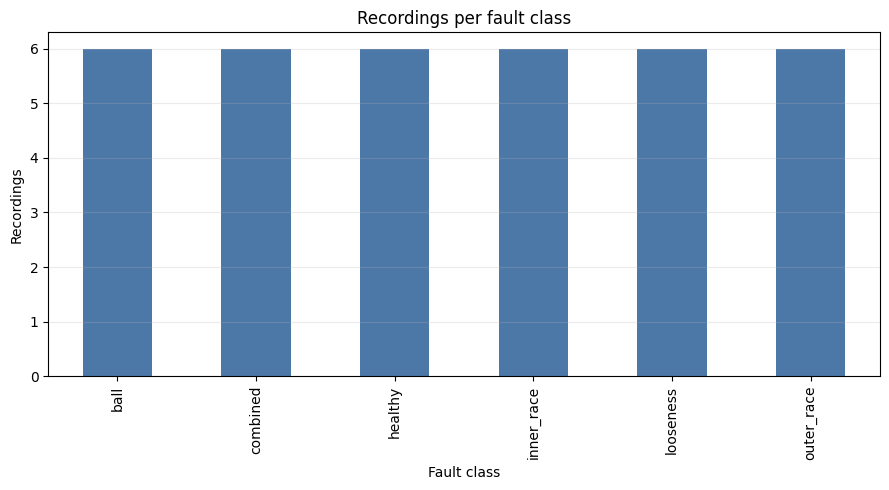

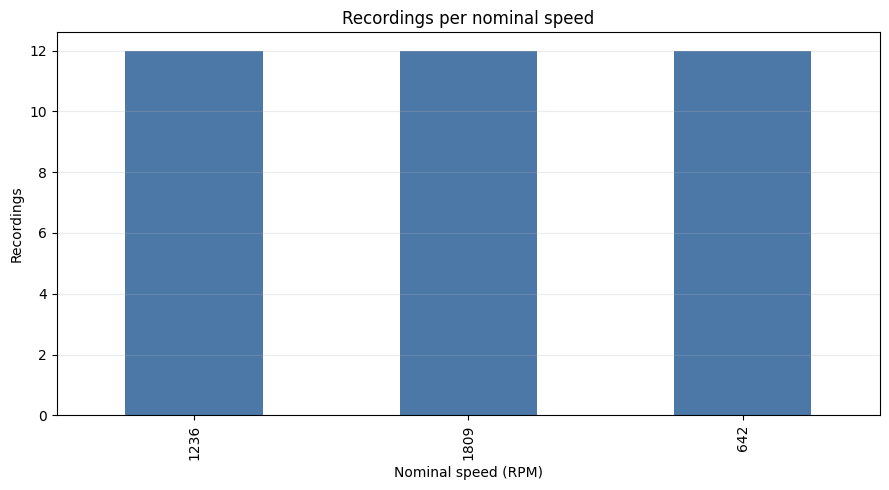

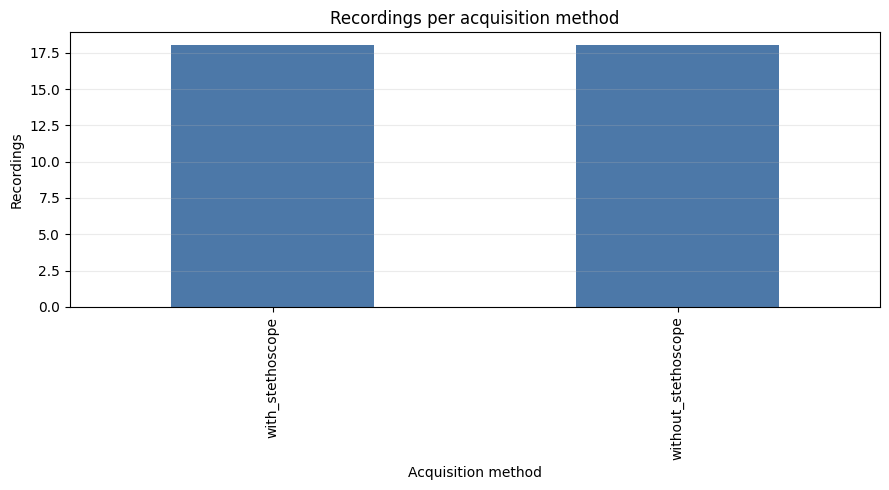

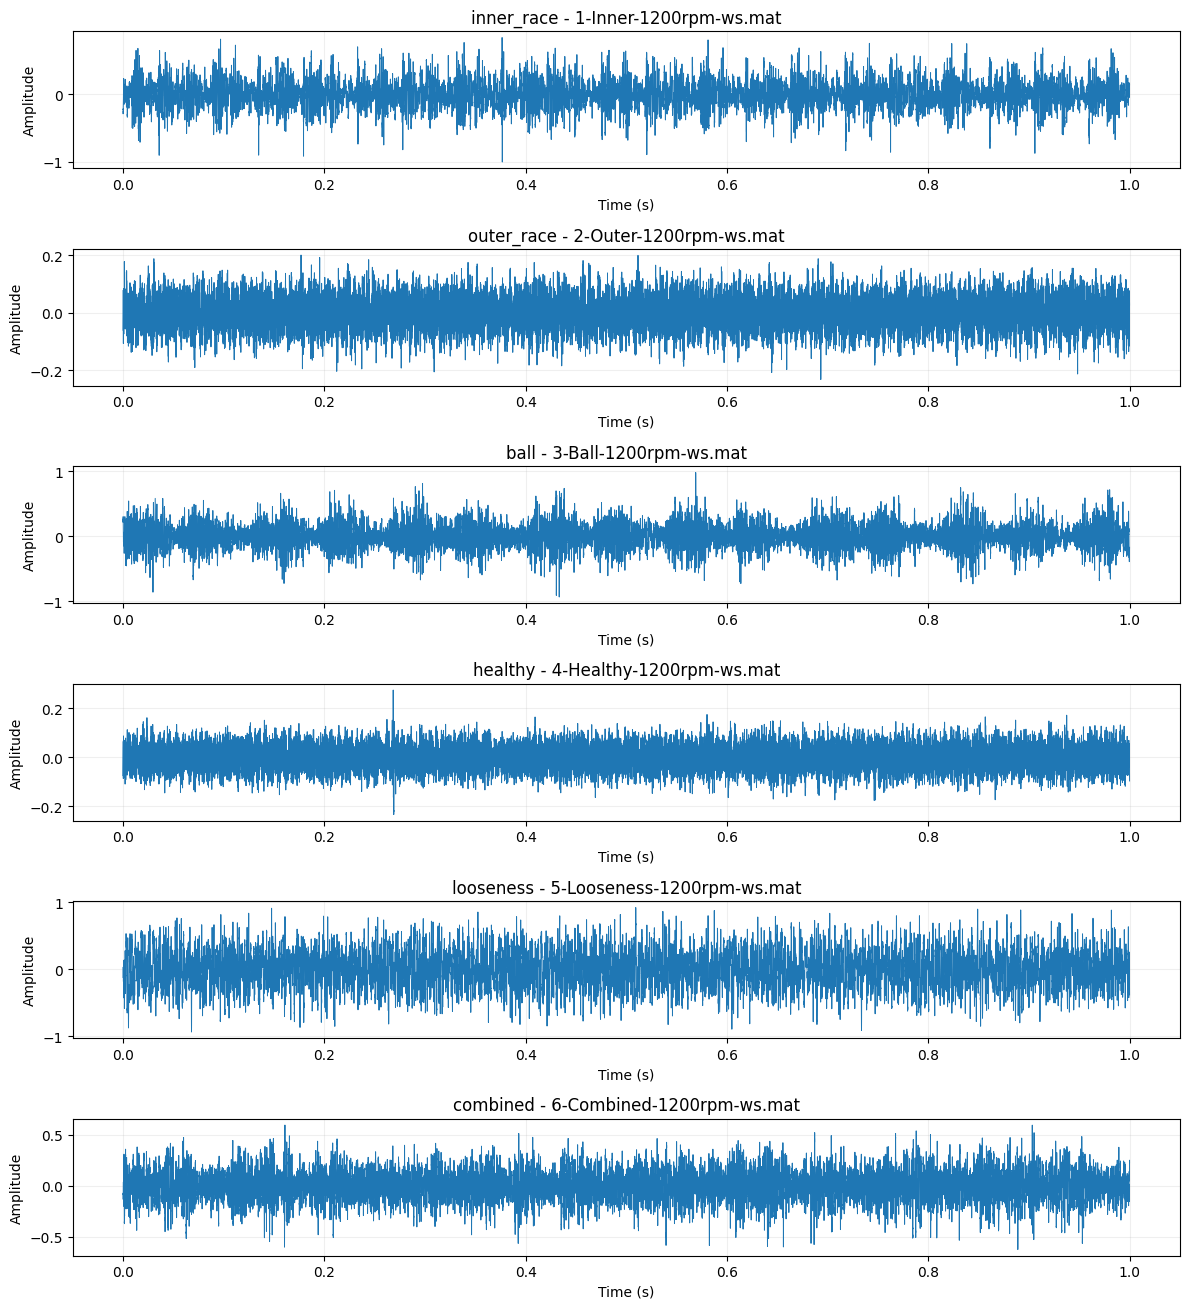

In [81]:
def save_bar(series, title, xlabel, ylabel, out_path):
    fig, ax = plt.subplots(figsize=(9, 5))
    series.plot(kind="bar", ax=ax, color="#4c78a8")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()


save_bar(recordings_df["fault"].value_counts().sort_index(), "Recordings per fault class", "Fault class", "Recordings", FIG_DIR / "recordings_per_fault.png")
save_bar(recordings_df["speed"].value_counts().sort_index(), "Recordings per nominal speed", "Nominal speed (RPM)", "Recordings", FIG_DIR / "recordings_per_speed.png")
save_bar(recordings_df["acquisition"].value_counts().sort_index(), "Recordings per acquisition method", "Acquisition method", "Recordings", FIG_DIR / "recordings_per_acquisition.png")

fault_examples = recordings_df.sort_values("filename").groupby("fault").head(1)
fig, axes = plt.subplots(len(fault_examples), 1, figsize=(12, 2.2 * len(fault_examples)), squeeze=False)
for ax, (_, row) in zip(axes[:, 0], fault_examples.iterrows()):
    loaded = load_mat_signal(row["filepath"])
    signal = loaded["signal"]
    sr = loaded["sample_rate"]
    n = min(len(signal), sr)
    t = np.arange(n) / sr
    ax.plot(t, signal[:n], linewidth=0.7)
    ax.set_title(f"{row['fault']} - {row['filename']}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIG_DIR / "sample_waveforms_by_fault.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Signal Segmentation

In [82]:
def build_segments(recordings: pd.DataFrame, segment_length: int, overlap: float) -> pd.DataFrame:
    hop = int(segment_length * (1.0 - overlap))
    if hop <= 0:
        raise ValueError("Overlap is too high; hop length must be positive.")

    rows = []
    max_segments = CONFIG["max_segments_per_recording"]
    for rec_idx, row in tqdm(list(recordings.reset_index(drop=True).iterrows()), desc="Building segment index"):
        total_samples = int(row["length_samples"])
        if total_samples < segment_length:
            continue
        starts = list(range(0, total_samples - segment_length + 1, hop))
        if max_segments > 0:
            starts = starts[:max_segments]
        for segment_id, start in enumerate(starts):
            rows.append(
                {
                    "recording_id": rec_idx,
                    "filepath": row["filepath"],
                    "filename": row["filename"],
                    "fault": row["fault"],
                    "speed": row["speed"],
                    "speed_rpm": row["speed_rpm"],
                    "acquisition": row["acquisition"],
                    "sample_rate": row["sample_rate"],
                    "signal_key": row["signal_key"],
                    "segment_id": segment_id,
                    "start_sample": int(start),
                    "end_sample": int(start + segment_length),
                }
            )
    return pd.DataFrame(rows)


segments_df = build_segments(recordings_df, CONFIG["segment_length"], CONFIG["overlap"])
if segments_df.empty:
    raise RuntimeError("No segments were created. Reduce segment_length or inspect recording durations.")

segments_df.to_csv(RESULTS_DIR / "segments_metadata.csv", index=False)
print(f"Window length: {CONFIG['segment_length']} samples. This captures local time-frequency structure while keeping CWT images computationally manageable.")
print(f"Created {len(segments_df)} segments from {segments_df['recording_id'].nunique()} recordings.")
display(segments_df.head())
display(segments_df.groupby("fault").size().reset_index(name="segments"))
display(segments_df.groupby("speed").size().reset_index(name="segments"))

Building segment index:   0%|          | 0/36 [00:00<?, ?it/s]

Window length: 4096 samples. This captures local time-frequency structure while keeping CWT images computationally manageable.
Created 11703 segments from 36 recordings.


,recording_id,filepath,filename,fault,speed,speed_rpm,acquisition,sample_rate,signal_key,segment_id,start_sample,end_sample
0,0,a:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions\Datasets 1- Data acquisition using the s...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,0,0,4096
1,0,a:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions\Datasets 1- Data acquisition using the s...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,1,2048,6144
2,0,a:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions\Datasets 1- Data acquisition using the s...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,2,4096,8192
3,0,a:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions\Datasets 1- Data acquisition using the s...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,3,6144,10240
4,0,a:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions\Datasets 1- Data acquisition using the s...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,4,8192,12288


,fault,segments
0,ball,2574
1,combined,1929
2,healthy,1476
3,inner_race,2574
4,looseness,1737
5,outer_race,1413


,speed,segments
0,1236,3901
1,1809,3901
2,642,3901


## 6. CWT Scalogram Generation

In [83]:
def scalogram_path(row: pd.Series) -> Path:
    stem = slugify(Path(row["filename"]).stem)
    return (
        SCALOGRAM_DIR
        / slugify(row["acquisition"])
        / slugify(row["speed"])
        / slugify(row["fault"])
        / f"{stem}_seg{int(row['segment_id']):05d}.png"
    )


def segment_to_scalogram(segment: np.ndarray, scales: np.ndarray, wavelet: str) -> np.ndarray:
    segment = segment.astype(np.float32, copy=False)
    segment = segment - np.mean(segment, dtype=np.float32)
    std = np.std(segment, dtype=np.float32)
    if std > 1e-8:
        segment = segment / std
    coeffs, _ = pywt.cwt(segment, scales, wavelet)
    power = np.abs(coeffs).astype(np.float32)
    power = np.log1p(power)
    lo, hi = np.percentile(power, [1, 99])
    power = np.clip((power - lo) / (hi - lo + 1e-8), 0, 1)
    gray = (power * 255).astype(np.uint8)
    return gray


def generate_scalograms(segments: pd.DataFrame) -> pd.DataFrame:
    segments = segments.copy()
    segments["image_path"] = segments.apply(lambda r: str(scalogram_path(r)), axis=1)
    missing = segments[~segments["image_path"].map(lambda p: Path(p).exists())]
    print(f"Total scalograms indexed: {len(segments)}")
    print(f"Already cached: {len(segments) - len(missing)}")
    print(f"To generate: {len(missing)}")

    errors = []
    for filepath, group in tqdm(missing.groupby("filepath"), total=missing["filepath"].nunique(), desc="Generating CWT by recording"):
        try:
            loaded = load_mat_signal(filepath)
            signal = loaded["signal"]
        except Exception as exc:
            errors.append({"filepath": filepath, "error": repr(exc)})
            continue

        for _, row in group.iterrows():
            out_path = Path(row["image_path"])
            if out_path.exists():
                continue
            try:
                segment = signal[int(row["start_sample"]):int(row["end_sample"])]
                image = segment_to_scalogram(segment, CONFIG["cwt_scales"], CONFIG["cwt_wavelet"])
                pil_image = Image.fromarray(image, mode="L").resize((CONFIG["image_size"], CONFIG["image_size"]), Image.Resampling.BICUBIC)
                out_path.parent.mkdir(parents=True, exist_ok=True)
                pil_image.save(out_path)
            except Exception as exc:
                errors.append({"filepath": filepath, "segment_id": int(row["segment_id"]), "error": repr(exc)})

    if errors:
        pd.DataFrame(errors).to_csv(LOG_DIR / "scalogram_generation_errors.csv", index=False)
        print(f"Logged {len(errors)} scalogram errors to {LOG_DIR / 'scalogram_generation_errors.csv'}")

    existing = segments[segments["image_path"].map(lambda p: Path(p).exists())].reset_index(drop=True)
    existing.to_csv(RESULTS_DIR / "scalograms_metadata.csv", index=False)
    print(f"Usable scalograms: {len(existing)}")
    return existing


scalograms_df = generate_scalograms(segments_df)
if scalograms_df.empty:
    raise RuntimeError("No scalogram images are available.")

display(scalograms_df.head())

Total scalograms indexed: 11703
Already cached: 11703
To generate: 0


Generating CWT by recording: 0it [00:00, ?it/s]

Usable scalograms: 11703


,recording_id,filepath,filename,fault,speed,speed_rpm,acquisition,sample_rate,signal_key,segment_id,start_sample,end_sample,image_path
0,0,a:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions\Datasets 1- Data acquisition using the s...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,0,0,4096,a:\AMU\IISA_2026\generated_scalograms\with_stethoscope\642\inner_race\first_speed_648_rpm_seg00000.png
1,0,a:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions\Datasets 1- Data acquisition using the s...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,1,2048,6144,a:\AMU\IISA_2026\generated_scalograms\with_stethoscope\642\inner_race\first_speed_648_rpm_seg00001.png
2,0,a:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions\Datasets 1- Data acquisition using the s...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,2,4096,8192,a:\AMU\IISA_2026\generated_scalograms\with_stethoscope\642\inner_race\first_speed_648_rpm_seg00002.png
3,0,a:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions\Datasets 1- Data acquisition using the s...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,3,6144,10240,a:\AMU\IISA_2026\generated_scalograms\with_stethoscope\642\inner_race\first_speed_648_rpm_seg00003.png
4,0,a:\AMU\IISA_2026\Sound Datasets of a Rolling Element Bearing under Various Operating Conditions\Datasets 1- Data acquisition using the s...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,4,8192,12288,a:\AMU\IISA_2026\generated_scalograms\with_stethoscope\642\inner_race\first_speed_648_rpm_seg00004.png


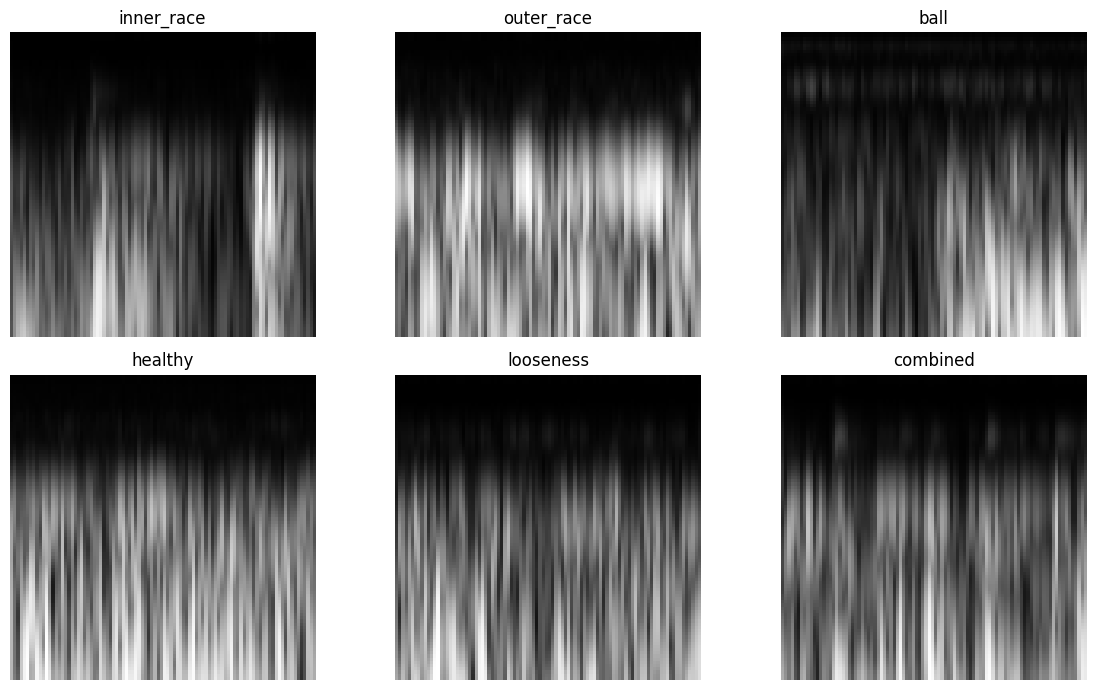

In [84]:
example_scalograms = scalograms_df.groupby("fault").head(1).reset_index(drop=True)
cols = min(3, len(example_scalograms))
rows = math.ceil(len(example_scalograms) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for ax, (_, row) in zip(axes.ravel(), example_scalograms.iterrows()):
    ax.imshow(Image.open(row["image_path"]), cmap="gray")
    ax.set_title(row["fault"])
fig.tight_layout()
fig.savefig(FIG_DIR / "sample_scalograms_by_fault.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. PyTorch Dataset

In [85]:
class CWTImageDataset(Dataset):
    def __init__(self, dataframe: pd.DataFrame, class_to_idx: dict[str, int], transform=None):
        self.df = dataframe.reset_index(drop=True).copy()
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, index: int):
        row = self.df.iloc[index]
        image = Image.open(row["image_path"]).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        label = self.class_to_idx[row["fault"]]
        meta = {
            "image_path": row["image_path"],
            "fault": row["fault"],
            "speed": row["speed"],
            "acquisition": row["acquisition"],
            "filename": row["filename"],
        }
        return image, label, meta


classes = sorted(scalograms_df["fault"].unique())
class_to_idx = {label: idx for idx, label in enumerate(classes)}
idx_to_class = {idx: label for label, idx in class_to_idx.items()}
num_classes = len(classes)

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]
eval_transform = transforms.Compose([
    transforms.Resize((CONFIG["image_size"], CONFIG["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])
train_transform = transforms.Compose([
    transforms.Resize((CONFIG["image_size"], CONFIG["image_size"])),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.03, 0.03),
        scale=(0.98, 1.02),
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std,
    ),

    transforms.RandomErasing(
        p=0.15,
        scale=(0.01, 0.05),
        ratio=(0.5, 2.0),
    ),
])


def make_loader(df: pd.DataFrame, split: str, shuffle: bool = False) -> DataLoader:
    dataset = CWTImageDataset(df, class_to_idx=class_to_idx, transform=train_transform if split == "train" else eval_transform)
    return DataLoader(
        dataset,
        batch_size=CONFIG["batch_size"],
        shuffle=shuffle,
        num_workers=CONFIG["num_workers"],
        pin_memory=(DEVICE.type == "cuda"),
    )


sample_loader = make_loader(scalograms_df.head(min(len(scalograms_df), CONFIG["batch_size"])), "test")
sample_images, sample_labels, sample_meta = next(iter(sample_loader))
print(f"Dataset size: {len(scalograms_df)}")
print(f"Class mapping: {class_to_idx}")
print(f"Sample batch image shape: {tuple(sample_images.shape)}")
print(f"Sample batch label shape: {tuple(sample_labels.shape)}")

Dataset size: 11703
Class mapping: {'ball': 0, 'combined': 1, 'healthy': 2, 'inner_race': 3, 'looseness': 4, 'outer_race': 5}
Sample batch image shape: (32, 3, 224, 224)
Sample batch label shape: (32,)


## 8. ResNet18 Model, Training, and Evaluation Utilities

In [86]:
def build_resnet18(num_classes: int) -> nn.Module:
    weights = None
    if os.environ.get("BEARING_USE_PRETRAINED", "1").lower() in {"1", "true", "yes"}:
        try:
            weights = models.ResNet18_Weights.DEFAULT
        except Exception:
            weights = None
    try:
        model = models.resnet18(weights=weights)
    except Exception as exc:
        print(f"Could not load pretrained ResNet18 weights ({exc}). Falling back to random initialization.")
        model = models.resnet18(weights=None)
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
    nn.Dropout(0.2),
    nn.Linear(in_features, num_classes),
    )
    for param in model.parameters():
        param.requires_grad = False
    for param in model.layer4.parameters():
        param.requires_grad = True
    for param in model.fc.parameters():
        param.requires_grad = True
    
    return model.to(DEVICE)


def move_batch_to_device(images, labels):
    return images.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)


def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.eval()
    running_loss = 0.0
    all_labels, all_preds = [], []
    for images, labels, _ in tqdm(loader, desc="Train", leave=False):
        images, labels = move_batch_to_device(images, labels)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        all_preds.extend(logits.argmax(dim=1).detach().cpu().numpy().tolist())
        all_labels.extend(labels.detach().cpu().numpy().tolist())
    avg_loss = running_loss / max(1, len(loader.dataset))
    avg_f1 = precision_recall_fscore_support(all_labels, all_preds, average="macro", zero_division=0)[2]
    return avg_loss, avg_f1


@torch.no_grad()
def evaluate_loss_and_f1(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    all_labels, all_preds = [], []
    for images, labels, _ in tqdm(loader, desc="Validate", leave=False):
        images, labels = move_batch_to_device(images, labels)
        logits = model(images)
        loss = criterion(logits, labels)
        running_loss += loss.item() * images.size(0)
        all_preds.extend(logits.argmax(dim=1).detach().cpu().numpy().tolist())
        all_labels.extend(labels.detach().cpu().numpy().tolist())
    avg_loss = running_loss / max(1, len(loader.dataset))
    avg_f1 = precision_recall_fscore_support(all_labels, all_preds, average="macro", zero_division=0)[2]
    return avg_loss, avg_f1


@torch.no_grad()
def predict(model, loader):
    model.eval()
    all_labels, all_preds, all_probs, all_meta = [], [], [], []
    start_time = time.perf_counter()
    for images, labels, metas in tqdm(loader, desc="Predict", leave=False):
        images = images.to(DEVICE, non_blocking=True)
        logits = model(images)
        probs = torch.softmax(logits, dim=1).detach().cpu().numpy()
        preds = probs.argmax(axis=1)
        all_probs.append(probs)
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.numpy().tolist())
        for i in range(len(labels)):
            all_meta.append({k: metas[k][i] for k in metas})
    elapsed = time.perf_counter() - start_time
    probs = np.vstack(all_probs) if all_probs else np.empty((0, num_classes))
    return np.array(all_labels), np.array(all_preds), probs, all_meta, elapsed


def compute_metrics(y_true, y_pred, y_prob):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),

        # Weighted metrics
        "weighted_precision": precision_score(
            y_true, y_pred,
            average="weighted",
            zero_division=0,
        ),
        "weighted_recall": recall_score(
            y_true, y_pred,
            average="weighted",
            zero_division=0,
        ),
        "weighted_f1": precision_recall_fscore_support(
            y_true, y_pred,
            average="weighted",
            zero_division=0,
        )[2],

        # Macro metrics
        "macro_precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0,
        ),
        "macro_recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0,
        ),
        "macro_f1": precision_recall_fscore_support(
            y_true, y_pred,
            average="macro",
            zero_division=0,
        )[2],
    }

    try:
        if len(np.unique(y_true)) > 1 and y_prob.shape[1] == num_classes:
            y_true_bin = label_binarize(
                y_true,
                classes=list(range(num_classes))
            )
            metrics["roc_auc"] = roc_auc_score(
                y_true_bin,
                y_prob,
                average="weighted",
                multi_class="ovr",
            )
        else:
            metrics["roc_auc"] = np.nan
    except Exception:
        metrics["roc_auc"] = np.nan

    return metrics

In [87]:
def plot_training_history(history_df, experiment_name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
    axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
    axes[0].set_title(f"{experiment_name} loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.25)
    axes[1].plot(history_df["epoch"], history_df["train_f1"], label="Train")
    axes[1].plot(history_df["epoch"], history_df["val_f1"], label="Validation")
    axes[1].set_title(f"{experiment_name} F1")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Weighted F1")
    axes[1].legend()
    axes[1].grid(alpha=0.25)
    fig.tight_layout()
    out_path = RESULTS_DIR / "training_curves" / f"{slugify(experiment_name)}_training_curves.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    return out_path


def plot_confusion_matrix(y_true, y_pred, experiment_name):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    fig.colorbar(im, ax=ax)
    ax.set(
        xticks=np.arange(num_classes),
        yticks=np.arange(num_classes),
        xticklabels=classes,
        yticklabels=classes,
        ylabel="True label",
        xlabel="Predicted label",
        title=f"{experiment_name} confusion matrix",
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    thresh = cm.max() / 2.0 if cm.max() else 0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], "d"), ha="center", va="center", color="white" if cm[i, j] > thresh else "black")
    fig.tight_layout()
    out_path = RESULTS_DIR / "confusion_matrices" / f"{slugify(experiment_name)}_confusion_matrix.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    return out_path


def plot_roc_curves(y_true, y_prob, experiment_name):
    y_true_bin = label_binarize(y_true, classes=list(range(num_classes)))
    fig, ax = plt.subplots(figsize=(8, 7))
    for idx, class_name in enumerate(classes):
        if y_true_bin[:, idx].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_true_bin[:, idx], y_prob[:, idx])
        ax.plot(fpr, tpr, label=f"{class_name} AUC={auc(fpr, tpr):.2f}")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set_title(f"{experiment_name} ROC curves")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
    fig.tight_layout()
    out_path = RESULTS_DIR / "roc_curves" / f"{slugify(experiment_name)}_roc_curves.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    return out_path


def save_classification_report(y_true, y_pred, experiment_name):
    report = classification_report(y_true, y_pred, target_names=classes, output_dict=True, zero_division=0)
    report_df = pd.DataFrame(report).T
    report_path = RESULTS_DIR / f"{slugify(experiment_name)}_classification_report.csv"
    report_df.to_csv(report_path)
    display(report_df)
    return report_df, report_path

In [88]:
def run_experiment(experiment_name, train_df, val_df, test_df):
    print(f"\n=== {experiment_name} ===")
    print(f"Train/Val/Test sizes: {len(train_df)} / {len(val_df)} / {len(test_df)}")
    display(pd.DataFrame({
        "train": train_df["fault"].value_counts(),
        "val": val_df["fault"].value_counts(),
        "test": test_df["fault"].value_counts(),
    }).fillna(0).astype(int))

    train_loader = make_loader(train_df, "train", shuffle=True)
    val_loader = make_loader(val_df, "val", shuffle=False)
    test_loader = make_loader(test_df, "test", shuffle=False)

    model = build_resnet18(num_classes)
    criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
    )
    optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"])
    scheduler = ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

    best_f1 = -np.inf
    best_epoch = -1
    patience_counter = 0
    history = []
    checkpoint_path = MODELS_DIR / f"best_resnet18_{slugify(experiment_name)}.pth"
    canonical_best_path = MODELS_DIR / "best_resnet18.pth"

    train_start = time.perf_counter()
    for epoch in range(1, CONFIG["epochs"] + 1):
        print(f"Epoch {epoch}/{CONFIG['epochs']}")
        train_loss, train_f1 = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_f1 = evaluate_loss_and_f1(model, val_loader, criterion)
        scheduler.step(val_f1)
        history.append({"epoch": epoch, "train_loss": train_loss, "train_f1": train_f1, "val_loss": val_loss, "val_f1": val_f1})
        print(f"train_loss={train_loss:.4f} train_f1={train_f1:.4f} val_loss={val_loss:.4f} val_f1={val_f1:.4f}")
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_epoch = epoch
            patience_counter = 0
            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "class_to_idx": class_to_idx,
                    "config": {k: str(v) for k, v in CONFIG.items() if k != "cwt_scales"},
                    "experiment": experiment_name,
                    "best_val_f1": float(best_f1),
                },
                checkpoint_path,
            )
            shutil.copyfile(checkpoint_path, canonical_best_path)
        else:
            patience_counter += 1
            if patience_counter >= CONFIG["patience"]:
                print(f"Early stopping after epoch {epoch}. Best epoch: {best_epoch}")
                break

    training_time = time.perf_counter() - train_start
    history_df = pd.DataFrame(history)
    history_df.to_csv(RESULTS_DIR / f"{slugify(experiment_name)}_training_history.csv", index=False)
    plot_training_history(history_df, experiment_name)

    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])

    y_true, y_pred, y_prob, metas, inference_time = predict(model, test_loader)
    metrics = compute_metrics(y_true, y_pred, y_prob)
    metrics.update({
        "experiment": experiment_name,
        "training_time_sec": training_time,
        "inference_time_sec": inference_time,
        "best_epoch": best_epoch,
        "checkpoint": str(checkpoint_path),
    })

    plot_confusion_matrix(y_true, y_pred, experiment_name)
    if len(np.unique(y_true)) > 1:
        plot_roc_curves(y_true, y_prob, experiment_name)
    report_df, report_path = save_classification_report(y_true, y_pred, experiment_name)

    predictions_df = pd.DataFrame(metas)
    predictions_df["true_label"] = [idx_to_class[int(i)] for i in y_true]
    predictions_df["pred_label"] = [idx_to_class[int(i)] for i in y_pred]
    predictions_df["correct"] = predictions_df["true_label"] == predictions_df["pred_label"]
    predictions_df.to_csv(RESULTS_DIR / f"{slugify(experiment_name)}_predictions.csv", index=False)
    report_df["Experiment"] = experiment_name
    print(pd.Series(metrics))
    
    return {
        "model": model,
        "metrics": metrics,
        "history": history_df,
        "report": report_df,
        "predictions": predictions_df,
        "test_loader": test_loader,
        "test_df": test_df,
        "checkpoint_path": checkpoint_path,
    }

## 9. Experiment 1 - Within-Speed Classification



Fold 1/5
Unique recordings
-----------------
Train: 22
Validation: 6
Test: 8

Scalograms
----------
Train: 6923
Validation: 1929
Test: 2851

=== Within Speed Fold 1 ===
Train/Val/Test sizes: 6923 / 1929 / 2851


,train,val,test
fault,,,
ball,1716,429,429
combined,1072,214,643
healthy,984,214,278
inner_race,1287,429,858
looseness,1309,214,214
outer_race,555,429,429


Epoch 1/10


Train:   0%|          | 0/217 [00:00<?, ?it/s]

Validate:   0%|          | 0/61 [00:00<?, ?it/s]

train_loss=0.6814 train_f1=0.8878 val_loss=1.3192 val_f1=0.5222
Epoch 2/10


... (5 outputs left out)

train_loss=0.4627 train_f1=0.9907 val_loss=1.5098 val_f1=0.4021
Epoch 4/10


Train:   0%|          | 0/217 [00:00<?, ?it/s]

Validate:   0%|          | 0/61 [00:00<?, ?it/s]

train_loss=0.4539 train_f1=0.9933 val_loss=1.4292 val_f1=0.4756
Early stopping after epoch 4. Best epoch: 1


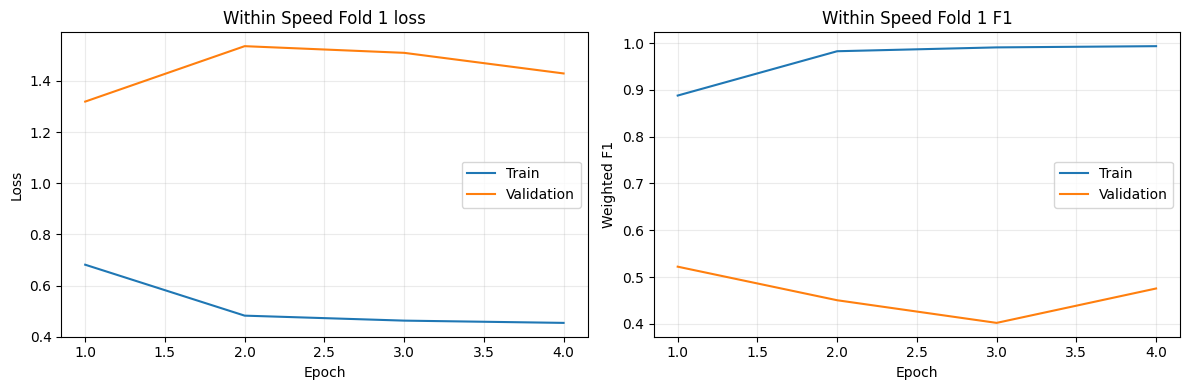

Predict:   0%|          | 0/90 [00:00<?, ?it/s]

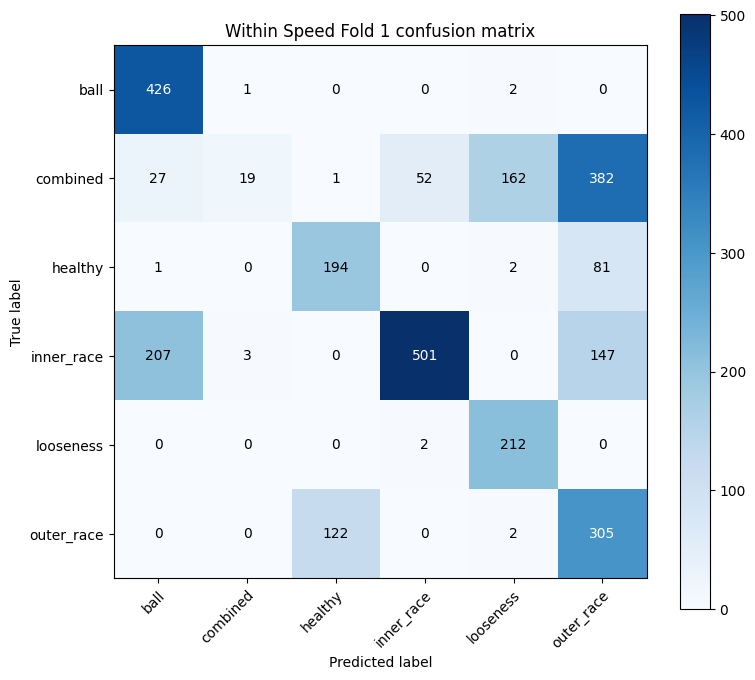

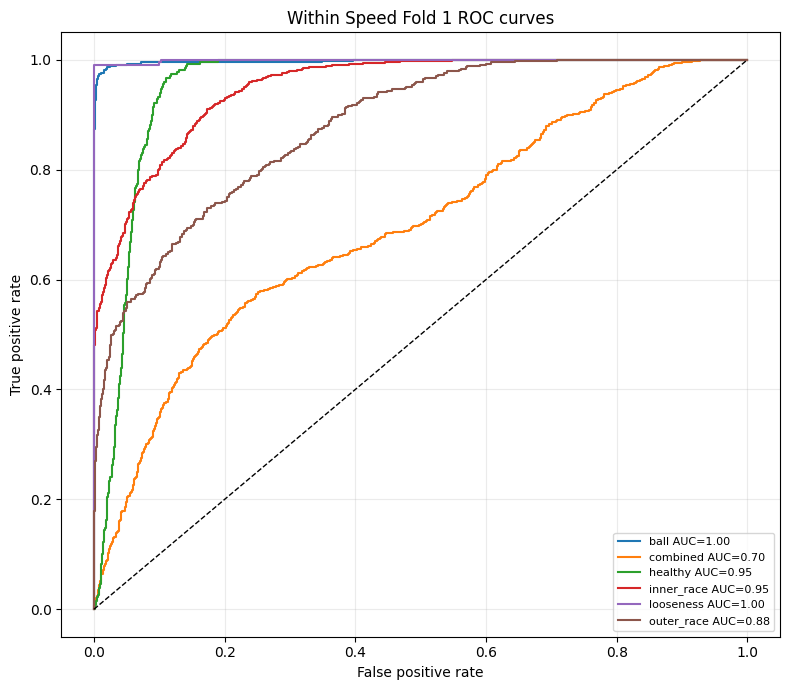

,precision,recall,f1-score,support
ball,0.644478,0.993007,0.781651,429.0000
combined,0.826087,0.029549,0.057057,643.0000
healthy,0.611987,0.697842,0.652101,278.0000
inner_race,0.902703,0.583916,0.709130,858.0000
looseness,0.557895,0.990654,0.713805,214.0000
outer_race,0.333333,0.710956,0.453869,429.0000
accuracy,0.581200,0.581200,0.581200,0.5812
macro avg,0.646081,0.667654,0.561269,2851.0000
weighted avg,0.706663,0.581200,0.529357,2851.0000


accuracy                                                                     0.5812
weighted_precision                                                         0.706663
weighted_recall                                                              0.5812
weighted_f1                                                                0.529357
macro_precision                                                            0.646081
macro_recall                                                               0.667654
macro_f1                                                                   0.561269
roc_auc                                                                    0.893042
experiment                                                      Within Speed Fold 1
training_time_sec                                                       1145.040219
inference_time_sec                                                        92.067713
best_epoch                                                                  

,train,val,test
fault,,,
ball,1716,429,429
combined,1286,214,429
healthy,1048,214,214
inner_race,1716,429,429
looseness,1158,365,214
outer_race,900,42,471


Epoch 1/10


Train:   0%|          | 0/245 [00:00<?, ?it/s]

Validate:   0%|          | 0/53 [00:00<?, ?it/s]

... (6 outputs left out)

train_loss=0.4679 train_f1=0.9904 val_loss=1.2557 val_f1=0.4461
Epoch 4/10


Train:   0%|          | 0/245 [00:00<?, ?it/s]

Validate:   0%|          | 0/53 [00:00<?, ?it/s]

train_loss=0.4569 train_f1=0.9932 val_loss=1.2850 val_f1=0.5271
Early stopping after epoch 4. Best epoch: 1


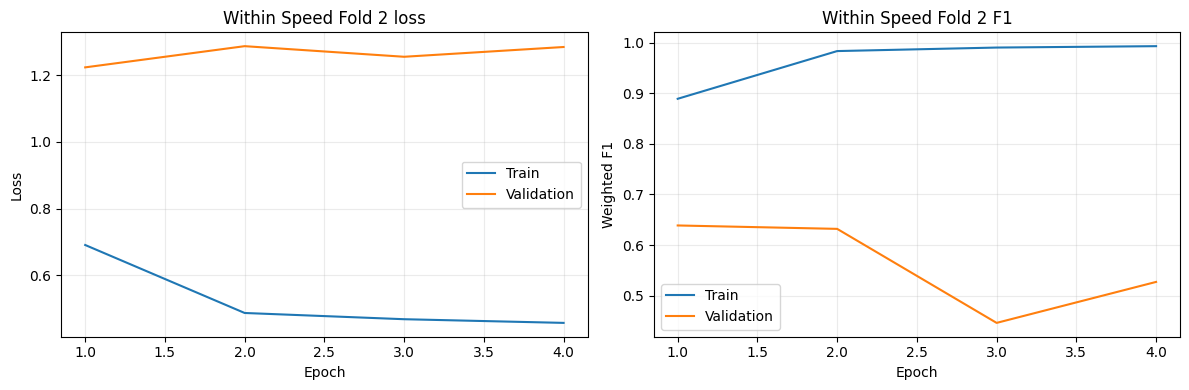

Predict:   0%|          | 0/69 [00:00<?, ?it/s]

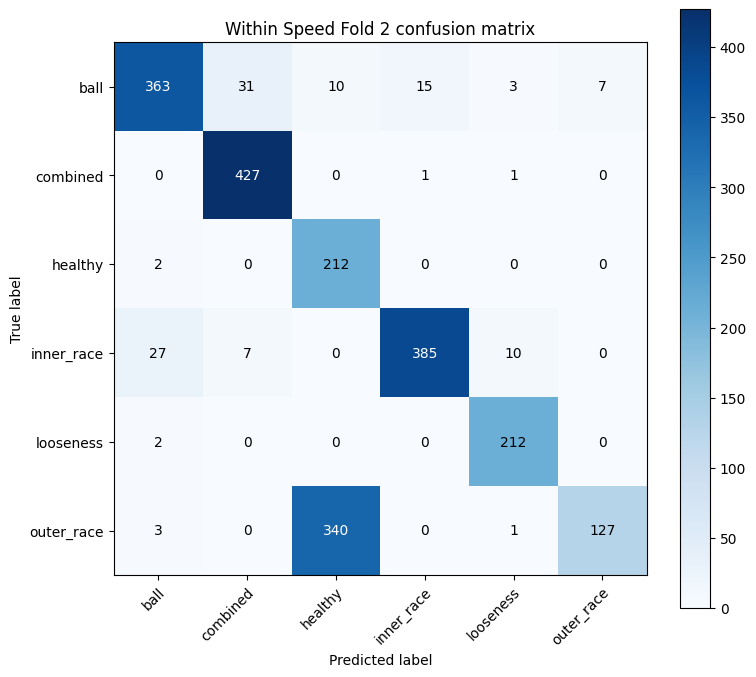

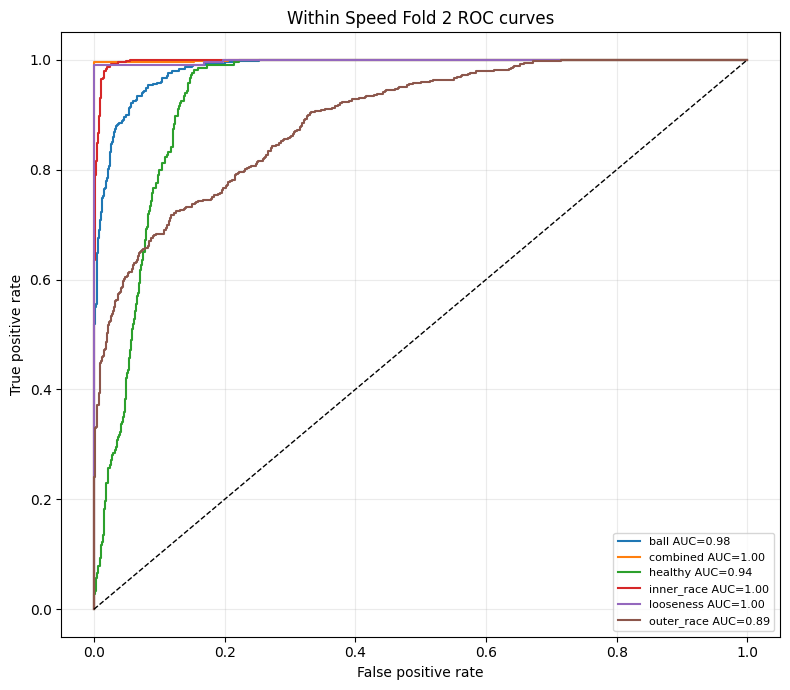

,precision,recall,f1-score,support
ball,0.914358,0.846154,0.878935,429.00000
combined,0.918280,0.995338,0.955257,429.00000
healthy,0.377224,0.990654,0.546392,214.00000
inner_race,0.960100,0.897436,0.927711,429.00000
looseness,0.933921,0.990654,0.961451,214.00000
outer_race,0.947761,0.269639,0.419835,471.00000
accuracy,0.789570,0.789570,0.789570,0.78957
macro avg,0.841941,0.831646,0.781597,2186.00000
weighted avg,0.880633,0.789570,0.780090,2186.00000


accuracy                                                                    0.78957
weighted_precision                                                         0.880633
weighted_recall                                                             0.78957
weighted_f1                                                                 0.78009
macro_precision                                                            0.841941
macro_recall                                                               0.831646
macro_f1                                                                   0.781597
roc_auc                                                                    0.966787
experiment                                                      Within Speed Fold 2
training_time_sec                                                       2087.090985
inference_time_sec                                                        56.252401
best_epoch                                                                  

,train,val,test
fault,,,
ball,1287,429,858
combined,1286,429,214
healthy,984,278,214
inner_race,1716,429,429
looseness,1158,214,365
outer_race,942,42,429


Epoch 1/10


Train:   0%|          | 0/231 [00:00<?, ?it/s]

Validate:   0%|          | 0/57 [00:00<?, ?it/s]

... (15 outputs left out)

train_loss=0.4414 train_f1=0.9977 val_loss=0.9664 val_f1=0.6513
Epoch 7/10


Train:   0%|          | 0/231 [00:00<?, ?it/s]

Validate:   0%|          | 0/57 [00:00<?, ?it/s]

train_loss=0.4433 train_f1=0.9946 val_loss=1.2093 val_f1=0.6168
Early stopping after epoch 7. Best epoch: 4


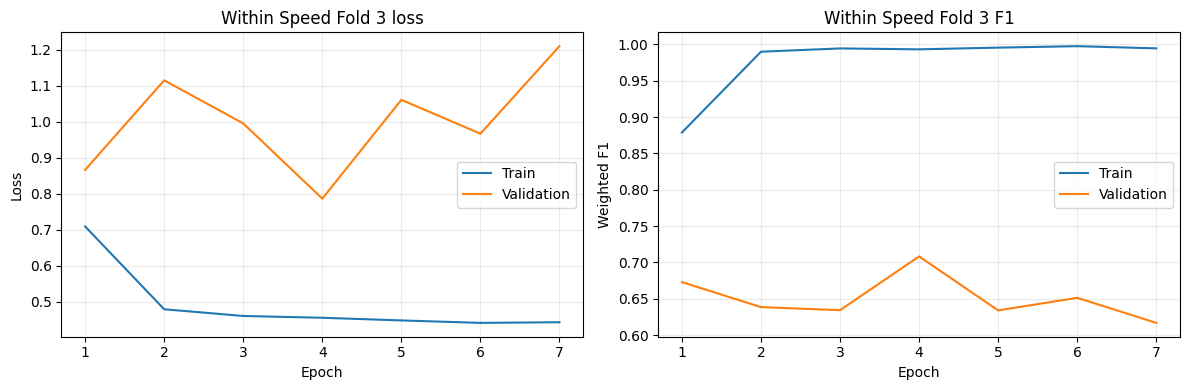

Predict:   0%|          | 0/79 [00:00<?, ?it/s]

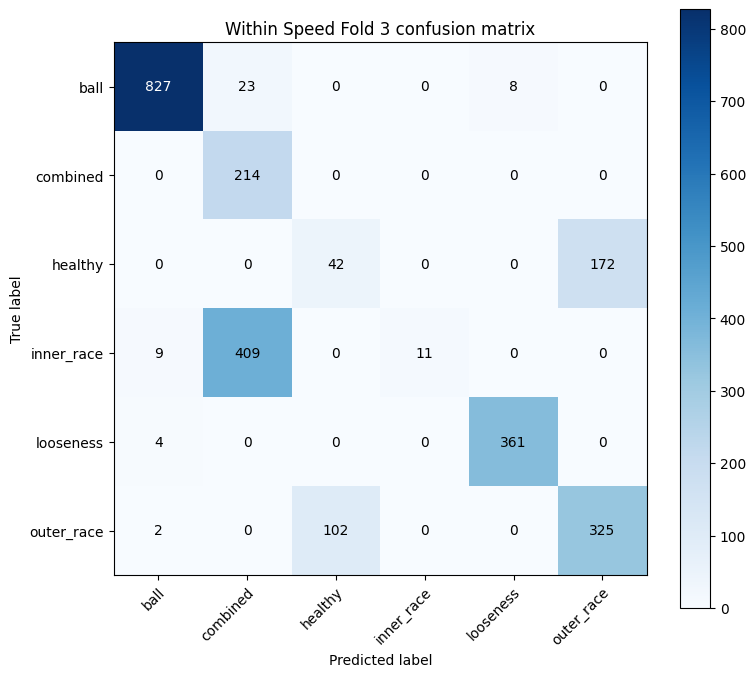

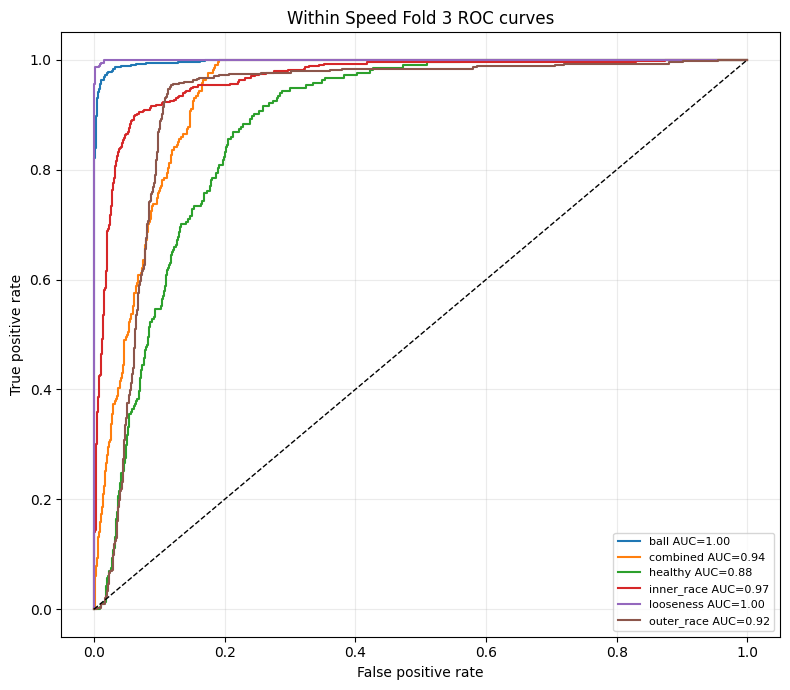

,precision,recall,f1-score,support
ball,0.982185,0.963869,0.972941,858.000000
combined,0.331269,1.000000,0.497674,214.000000
healthy,0.291667,0.196262,0.234637,214.000000
inner_race,1.000000,0.025641,0.050000,429.000000
looseness,0.978320,0.989041,0.983651,365.000000
outer_race,0.653924,0.757576,0.701944,429.000000
accuracy,0.709446,0.709446,0.709446,0.709446
macro avg,0.706227,0.655398,0.573475,2509.000000
weighted avg,0.814126,0.709446,0.666845,2509.000000


accuracy                                                                   0.709446
weighted_precision                                                         0.814126
weighted_recall                                                            0.709446
weighted_f1                                                                0.666845
macro_precision                                                            0.706227
macro_recall                                                               0.655398
macro_f1                                                                   0.573475
roc_auc                                                                    0.964209
experiment                                                      Within Speed Fold 3
training_time_sec                                                       1887.688539
inference_time_sec                                                        57.372984
best_epoch                                                                  

,train,val,test
fault,,,
ball,1716,429,429
combined,1286,429,214
healthy,770,214,492
inner_race,1716,429,429
looseness,1309,214,214
outer_race,1329,42,42


Epoch 1/10


Train:   0%|          | 0/254 [00:00<?, ?it/s]

Validate:   0%|          | 0/55 [00:00<?, ?it/s]

... (9 outputs left out)

train_loss=0.4512 train_f1=0.9946 val_loss=0.9513 val_f1=0.6224
Epoch 5/10


Train:   0%|          | 0/254 [00:00<?, ?it/s]

Validate:   0%|          | 0/55 [00:00<?, ?it/s]

train_loss=0.4471 train_f1=0.9958 val_loss=0.9330 val_f1=0.6783
Early stopping after epoch 5. Best epoch: 2


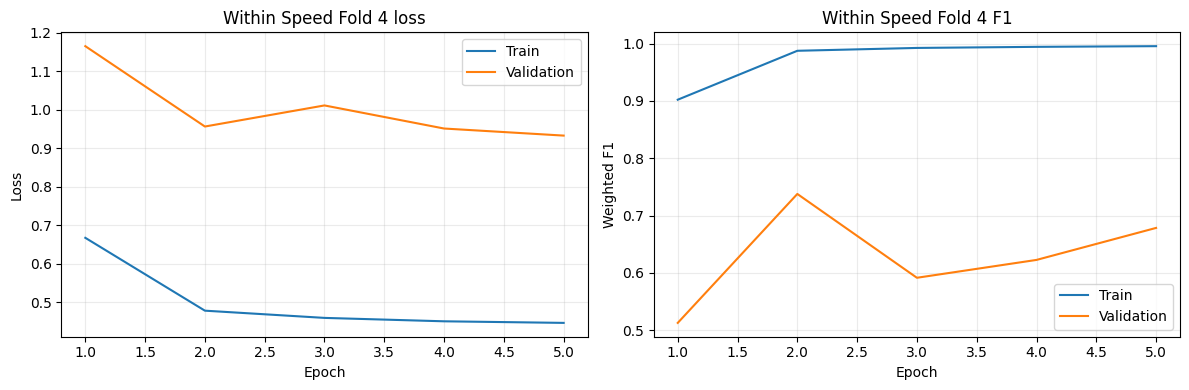

C:\Users\Ahmad Zakariya\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\torch\_guards.py:1551: ResourceWarning: unclosed file <_io.BufferedReader name='a:\\AMU\\IISA_2026\\generated_scalograms\\without_stethoscope\\642\\inner_race\\1_inner_600rpm_ws_seg00005.png'>
  if isinstance(flat_input, FakeTensor):


Predict:   0%|          | 0/57 [00:00<?, ?it/s]

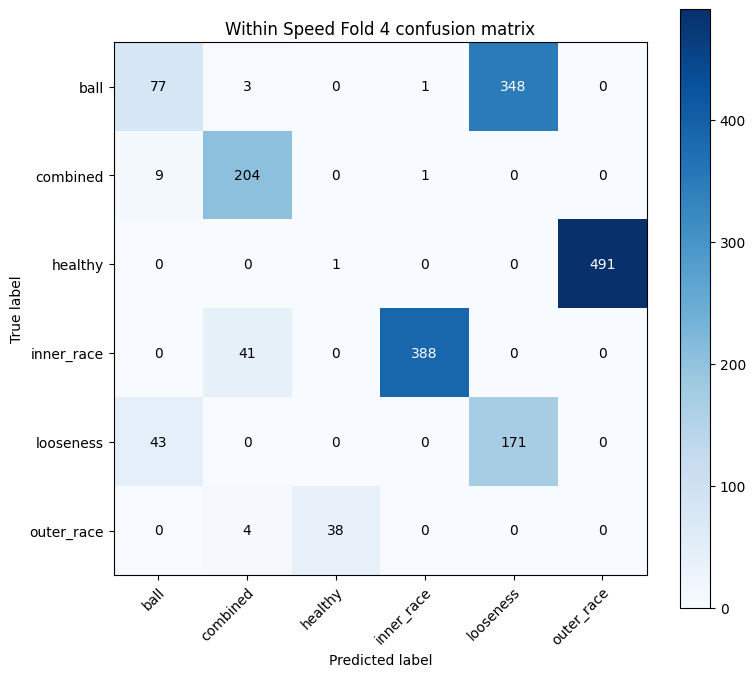

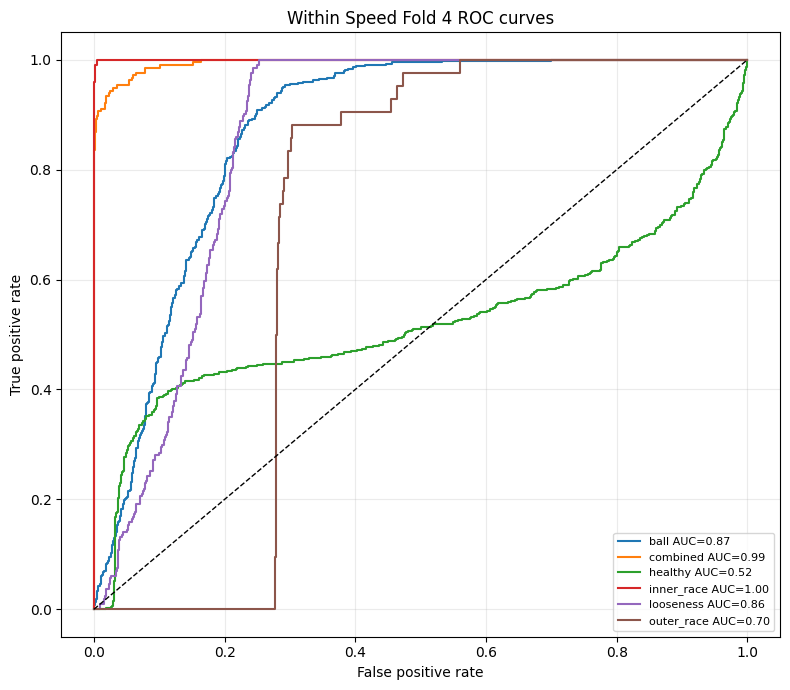

,precision,recall,f1-score,support
ball,0.596899,0.179487,0.275986,429.000000
combined,0.809524,0.953271,0.875536,214.000000
healthy,0.025641,0.002033,0.003766,492.000000
inner_race,0.994872,0.904429,0.947497,429.000000
looseness,0.329480,0.799065,0.466576,214.000000
outer_race,0.000000,0.000000,0.000000,42.000000
accuracy,0.462088,0.462088,0.462088,0.462088
macro avg,0.459403,0.473048,0.428227,1820.000000
weighted avg,0.516061,0.462088,0.447219,1820.000000


accuracy                                                                   0.462088
weighted_precision                                                         0.516061
weighted_recall                                                            0.462088
weighted_f1                                                                0.447219
macro_precision                                                            0.459403
macro_recall                                                               0.473048
macro_f1                                                                   0.428227
roc_auc                                                                    0.816248
experiment                                                      Within Speed Fold 4
training_time_sec                                                        1472.14402
inference_time_sec                                                        42.277025
best_epoch                                                                  

,train,val,test
fault,,,
ball,1716,429,429
combined,1286,214,429
healthy,984,214,278
inner_race,1716,429,429
looseness,793,214,730
outer_race,1329,42,42


Epoch 1/10


Train:   0%|          | 0/245 [00:00<?, ?it/s]

Validate:   0%|          | 0/49 [00:00<?, ?it/s]

... (12 outputs left out)

train_loss=0.4496 train_f1=0.9952 val_loss=1.6731 val_f1=0.3771
Epoch 6/10


Train:   0%|          | 0/245 [00:00<?, ?it/s]

Validate:   0%|          | 0/49 [00:00<?, ?it/s]

train_loss=0.4449 train_f1=0.9966 val_loss=1.5495 val_f1=0.3659
Early stopping after epoch 6. Best epoch: 3


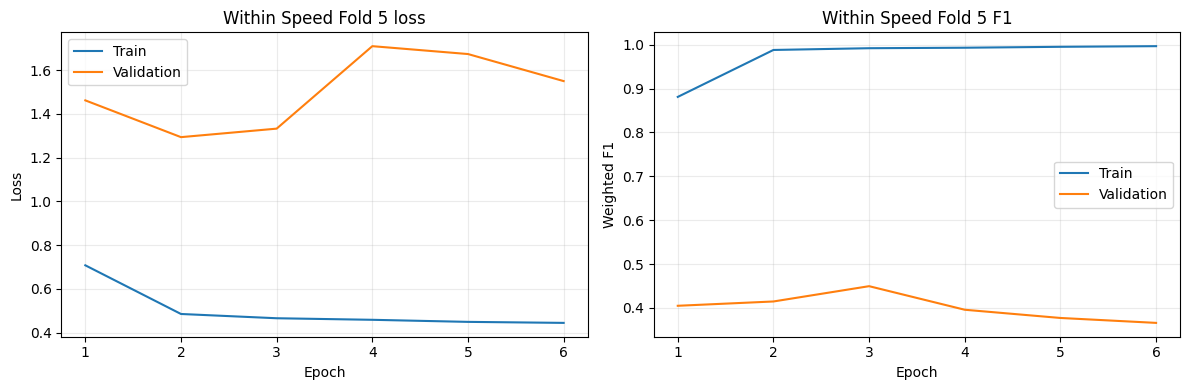

Predict:   0%|          | 0/74 [00:00<?, ?it/s]

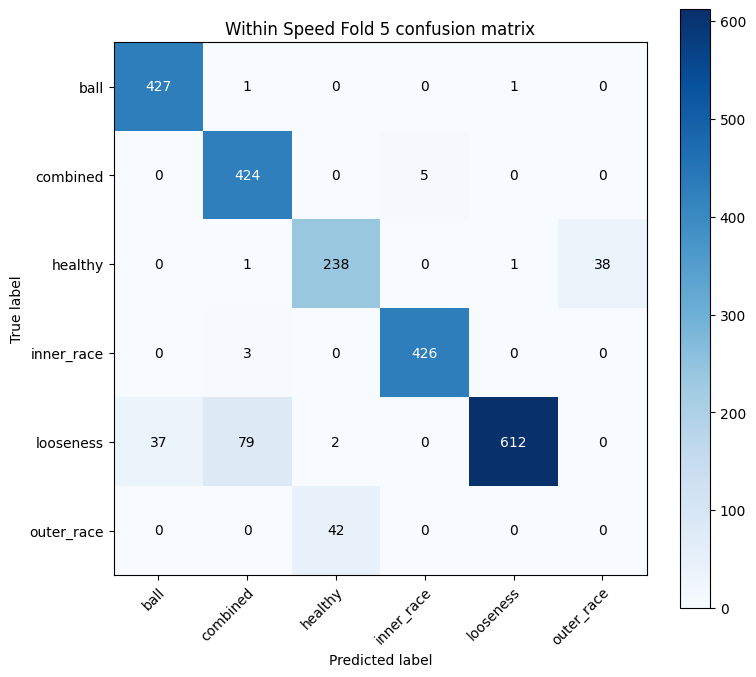

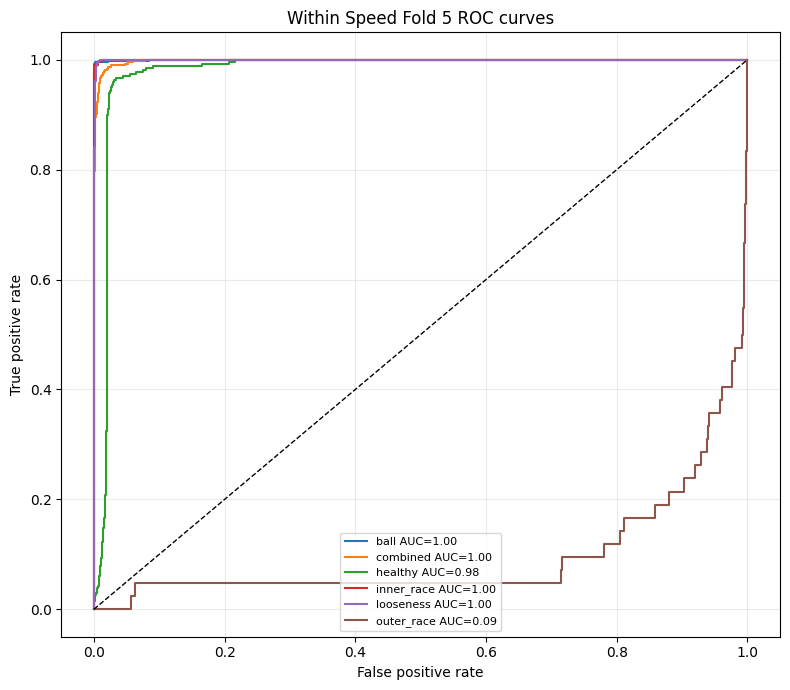

,precision,recall,f1-score,support
ball,0.920259,0.995338,0.956327,429.000000
combined,0.834646,0.988345,0.905016,429.000000
healthy,0.843972,0.856115,0.850000,278.000000
inner_race,0.988399,0.993007,0.990698,429.000000
looseness,0.996743,0.838356,0.910714,730.000000
outer_race,0.000000,0.000000,0.000000,42.000000
accuracy,0.910141,0.910141,0.910141,0.910141
macro avg,0.764003,0.778527,0.768792,2337.000000
weighted avg,0.915329,0.910141,0.909134,2337.000000


accuracy                                                                   0.910141
weighted_precision                                                         0.915329
weighted_recall                                                            0.910141
weighted_f1                                                                0.909134
macro_precision                                                            0.764003
macro_recall                                                               0.778527
macro_f1                                                                   0.768792
roc_auc                                                                    0.980752
experiment                                                      Within Speed Fold 5
training_time_sec                                                         1685.6935
inference_time_sec                                                        54.836241
best_epoch                                                                  

,accuracy,weighted_precision,weighted_recall,weighted_f1,macro_precision,macro_recall,macro_f1,roc_auc,experiment,training_time_sec,inference_time_sec,best_epoch,checkpoint
0,0.581200,0.706663,0.581200,0.529357,0.646081,0.667654,0.561269,0.893042,Within Speed Fold 1,1145.040219,92.067713,1,a:\AMU\IISA_2026\models\best_resnet18_within_speed_fold_1.pth
1,0.789570,0.880633,0.789570,0.780090,0.841941,0.831646,0.781597,0.966787,Within Speed Fold 2,2087.090985,56.252401,1,a:\AMU\IISA_2026\models\best_resnet18_within_speed_fold_2.pth
2,0.709446,0.814126,0.709446,0.666845,0.706227,0.655398,0.573475,0.964209,Within Speed Fold 3,1887.688539,57.372984,4,a:\AMU\IISA_2026\models\best_resnet18_within_speed_fold_3.pth
3,0.462088,0.516061,0.462088,0.447219,0.459403,0.473048,0.428227,0.816248,Within Speed Fold 4,1472.144020,42.277025,2,a:\AMU\IISA_2026\models\best_resnet18_within_speed_fold_4.pth
4,0.910141,0.915329,0.910141,0.909134,0.764003,0.778527,0.768792,0.980752,Within Speed Fold 5,1685.693500,54.836241,3,a:\AMU\IISA_2026\models\best_resnet18_within_speed_fold_5.pth




5-FOLD CROSS VALIDATION RESULTS


,Mean,Std
accuracy,0.690489,0.175025
weighted_precision,0.766563,0.161047
weighted_recall,0.690489,0.175025
weighted_f1,0.666529,0.186190
macro_precision,0.683531,0.144672
macro_recall,0.681254,0.138097
macro_f1,0.622672,0.150506
roc_auc,0.924208,0.069349
training_time_sec,1655.531453,365.815029
inference_time_sec,60.561273,18.631137


In [89]:
# ==========================================================
# 5-Fold Stratified Cross Validation (recording-level)
# ==========================================================

recordings = (
    scalograms_df[["recording_id", "fault"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

all_fold_metrics = []
all_fold_reports = []

for fold, (train_index, test_index) in enumerate(
    skf.split(recordings["recording_id"], recordings["fault"]),
    start=1,
):

    print("\n")
    print("=" * 70)
    print(f"Fold {fold}/5")
    print("=" * 70)

    train_rec = recordings.iloc[train_index].reset_index(drop=True)
    test_rec = recordings.iloc[test_index].reset_index(drop=True)

    #
    # Create validation recordings from training recordings
    #

    train_rec, val_rec = train_test_split(
        train_rec,
        test_size=0.2,
        random_state=SEED,
        stratify=train_rec["fault"],
    )

    train_df = scalograms_df[
        scalograms_df["recording_id"].isin(train_rec["recording_id"])
    ].reset_index(drop=True)

    val_df = scalograms_df[
        scalograms_df["recording_id"].isin(val_rec["recording_id"])
    ].reset_index(drop=True)

    test_df = scalograms_df[
        scalograms_df["recording_id"].isin(test_rec["recording_id"])
    ].reset_index(drop=True)

    #
    # Leakage check
    #

    assert (
        set(train_df.recording_id)
        & set(val_df.recording_id)
    ) == set()

    assert (
        set(train_df.recording_id)
        & set(test_df.recording_id)
    ) == set()

    assert (
        set(val_df.recording_id)
        & set(test_df.recording_id)
    ) == set()

    #
    # Statistics
    #

    print("Unique recordings")
    print("-----------------")
    print("Train:", train_df.recording_id.nunique())
    print("Validation:", val_df.recording_id.nunique())
    print("Test:", test_df.recording_id.nunique())

    print()

    print("Scalograms")
    print("----------")
    print("Train:", len(train_df))
    print("Validation:", len(val_df))
    print("Test:", len(test_df))

    #
    # Train
    #

    result = run_experiment(
        f"Within Speed Fold {fold}",
        train_df,
        val_df,
        test_df,
    )

    all_fold_metrics.append(result["metrics"])
    all_fold_reports.append(result["report"])

#
# ==========================================================
# Cross-validation summary
# ==========================================================
#

results_df = pd.DataFrame(all_fold_metrics)

display(results_df)

print("\n")
print("=" * 60)
print("5-FOLD CROSS VALIDATION RESULTS")
print("=" * 60)

numeric_cols = results_df.select_dtypes(include=np.number).columns

summary = pd.DataFrame({
    "Mean": results_df[numeric_cols].mean(),
    "Std": results_df[numeric_cols].std()
})

display(summary)

summary.to_csv(
    RESULTS_DIR / "within_speed_cross_validation_summary.csv"
)

results_df.to_csv(
    RESULTS_DIR / "within_speed_fold_results.csv",
    index=False,
)

## 10. Experiment 2 - Cross-Speed Generalization


Cross-Speed Stratified 5-Fold Summary

Fold 1
--------------------------
Train recordings : 18
Validation recordings : 6
Test recordings : 12
Train scalograms : 5981
Validation scalograms : 1821
Test scalograms : 3901

Fold 2
--------------------------
Train recordings : 18
Validation recordings : 6
Test recordings : 12
Train scalograms : 5443
Validation scalograms : 2359
Test scalograms : 3901

Fold 3
--------------------------
Train recordings : 18
Validation recordings : 6
Test recordings : 12
Train scalograms : 6109
Validation scalograms : 1693
Test scalograms : 3901

Fold 4
--------------------------
Train recordings : 18
Validation recordings : 6
Test recordings : 12
Train scalograms : 5873
Validation scalograms : 1929
Test scalograms : 3901


Cross-Speed Fold 1

=== Cross Speed Fold 1 ===
Train/Val/Test sizes: 5981 / 1821 / 3901


,train,val,test
fault,,,
ball,1287,429,858
combined,857,429,643
healthy,706,278,492
inner_race,1287,429,858
looseness,944,214,579
outer_race,900,42,471


Epoch 1/10


Train:   0%|          | 0/187 [00:00<?, ?it/s]

Validate:   0%|          | 0/57 [00:00<?, ?it/s]

train_loss=0.7264 train_f1=0.8703 val_loss=1.5316 val_f1=0.3463
Epoch 2/10


... (8 outputs left out)

train_loss=0.4577 train_f1=0.9949 val_loss=1.3026 val_f1=0.4821
Epoch 5/10


Train:   0%|          | 0/187 [00:00<?, ?it/s]

Validate:   0%|          | 0/57 [00:00<?, ?it/s]

train_loss=0.4519 train_f1=0.9962 val_loss=1.4395 val_f1=0.4331
Early stopping after epoch 5. Best epoch: 2


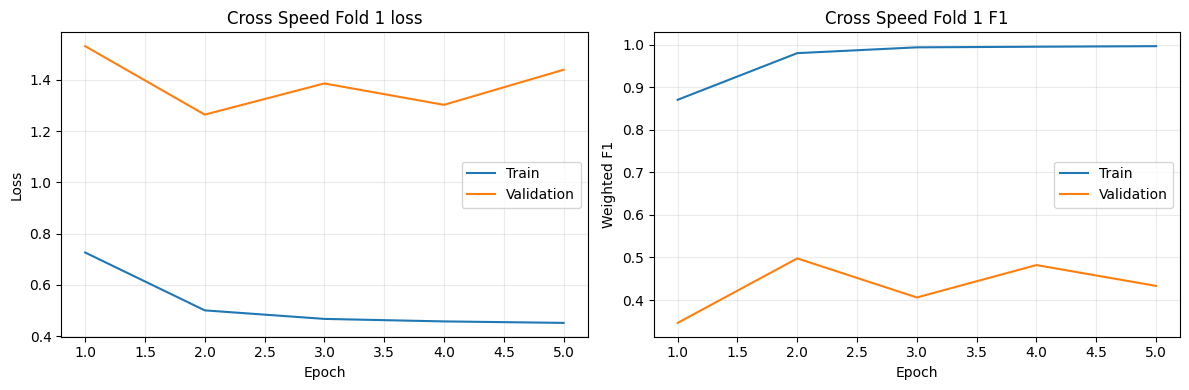

Predict:   0%|          | 0/122 [00:00<?, ?it/s]

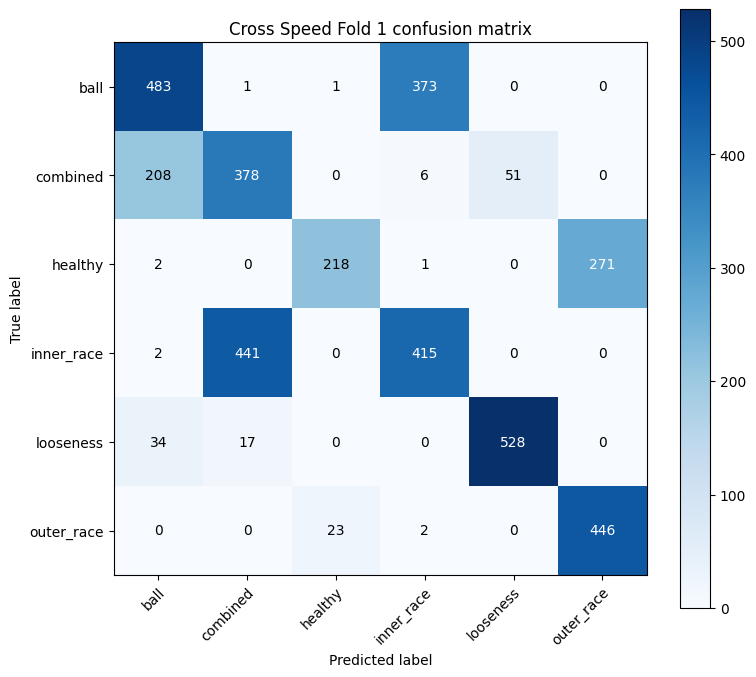

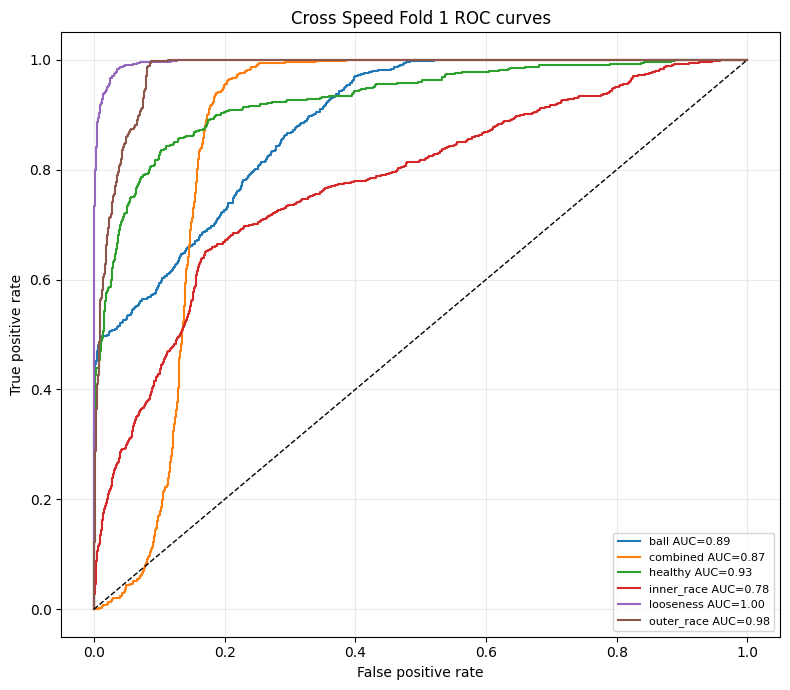

,precision,recall,f1-score,support
ball,0.662551,0.562937,0.608696,858.000000
combined,0.451613,0.587869,0.510811,643.000000
healthy,0.900826,0.443089,0.594005,492.000000
inner_race,0.520703,0.483683,0.501511,858.000000
looseness,0.911917,0.911917,0.911917,579.000000
outer_race,0.622036,0.946921,0.750842,471.000000
accuracy,0.632658,0.632658,0.632658,0.632658
macro avg,0.678274,0.656070,0.646297,3901.000000
weighted avg,0.658755,0.632658,0.629302,3901.000000


accuracy                                                                  0.632658
weighted_precision                                                        0.658755
weighted_recall                                                           0.632658
weighted_f1                                                               0.629302
macro_precision                                                           0.678274
macro_recall                                                               0.65607
macro_f1                                                                  0.646297
roc_auc                                                                   0.892287
experiment                                                      Cross Speed Fold 1
training_time_sec                                                      1139.749137
inference_time_sec                                                       87.748707
best_epoch                                                                       2
chec

,train,val,test
fault,,,
ball,1287,429,858
combined,857,429,643
healthy,706,278,492
inner_race,1287,429,858
looseness,793,365,579
outer_race,513,429,471


Epoch 1/10


Train:   0%|          | 0/171 [00:00<?, ?it/s]

Validate:   0%|          | 0/74 [00:00<?, ?it/s]

... (9 outputs left out)

train_loss=0.4687 train_f1=0.9889 val_loss=0.9966 val_f1=0.6476
Epoch 5/10


Train:   0%|          | 0/171 [00:00<?, ?it/s]

Validate:   0%|          | 0/74 [00:00<?, ?it/s]

train_loss=0.4585 train_f1=0.9923 val_loss=0.9047 val_f1=0.7081
Early stopping after epoch 5. Best epoch: 2


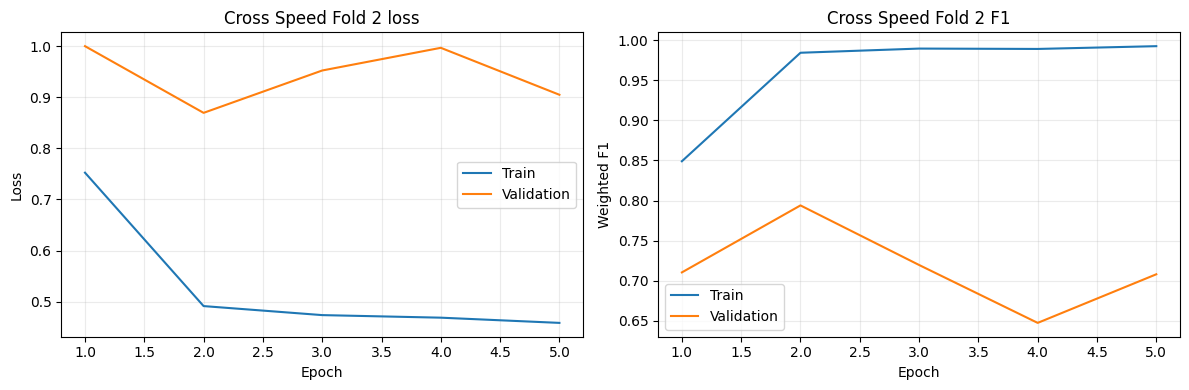

Predict:   0%|          | 0/122 [00:00<?, ?it/s]

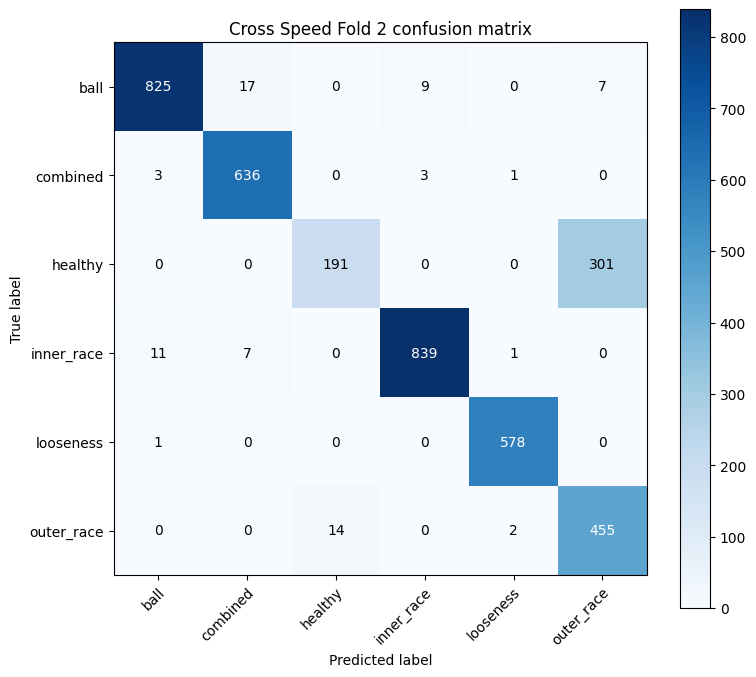

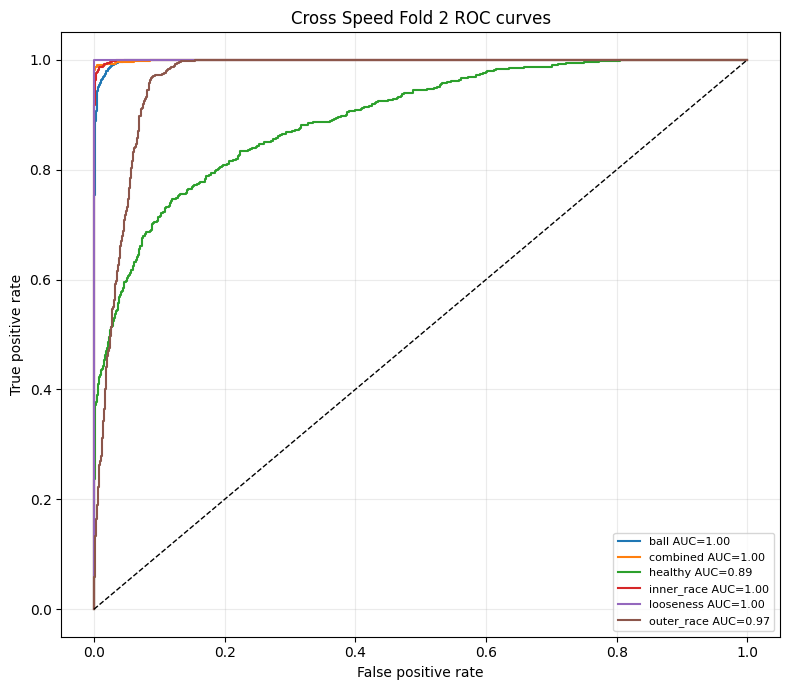

,precision,recall,f1-score,support
ball,0.982143,0.961538,0.971731,858.000000
combined,0.963636,0.989114,0.976209,643.000000
healthy,0.931707,0.388211,0.548063,492.000000
inner_race,0.985899,0.977855,0.981861,858.000000
looseness,0.993127,0.998273,0.995693,579.000000
outer_race,0.596330,0.966030,0.737439,471.000000
accuracy,0.903358,0.903358,0.903358,0.903358
macro avg,0.908807,0.880170,0.868499,3901.000000
weighted avg,0.928606,0.903358,0.896532,3901.000000


accuracy                                                                  0.903358
weighted_precision                                                        0.928606
weighted_recall                                                           0.903358
weighted_f1                                                               0.896532
macro_precision                                                           0.908807
macro_recall                                                               0.88017
macro_f1                                                                  0.868499
roc_auc                                                                   0.982121
experiment                                                      Cross Speed Fold 2
training_time_sec                                                      1207.933774
inference_time_sec                                                       96.850816
best_epoch                                                                       2
chec

,train,val,test
fault,,,
ball,1287,429,858
combined,1072,214,643
healthy,770,214,492
inner_race,1287,429,858
looseness,793,365,579
outer_race,900,42,471


Epoch 1/10


Train:   0%|          | 0/191 [00:00<?, ?it/s]

Validate:   0%|          | 0/53 [00:00<?, ?it/s]

... (12 outputs left out)

train_loss=0.4532 train_f1=0.9954 val_loss=1.2712 val_f1=0.4509
Epoch 6/10


Train:   0%|          | 0/191 [00:00<?, ?it/s]

Validate:   0%|          | 0/53 [00:00<?, ?it/s]

train_loss=0.4441 train_f1=0.9973 val_loss=1.2780 val_f1=0.4719
Early stopping after epoch 6. Best epoch: 3


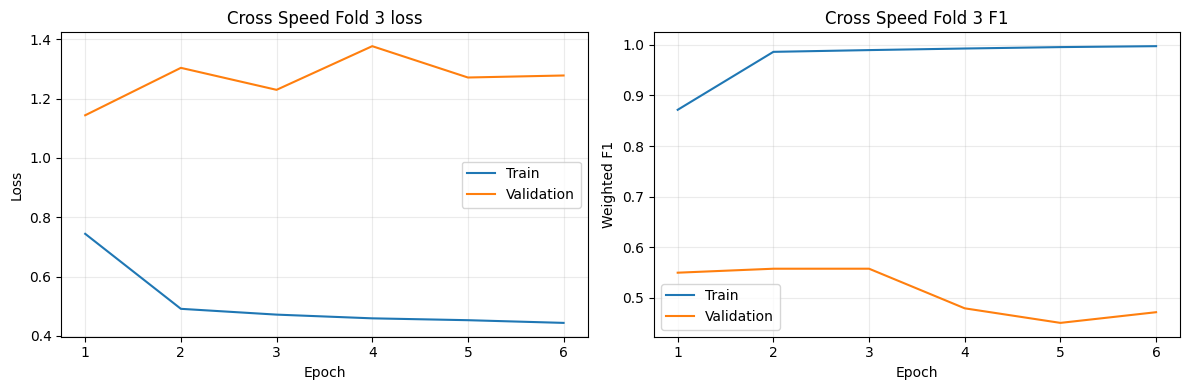

Predict:   0%|          | 0/122 [00:00<?, ?it/s]

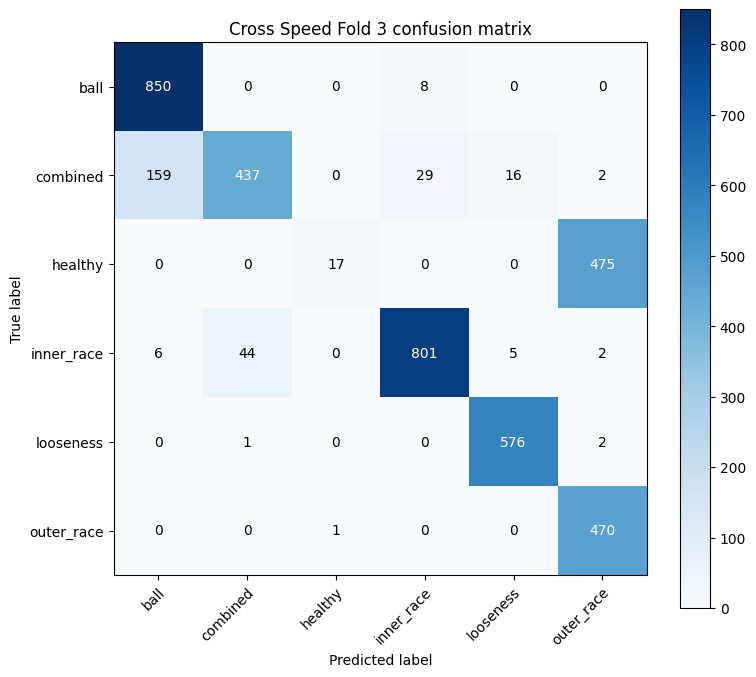

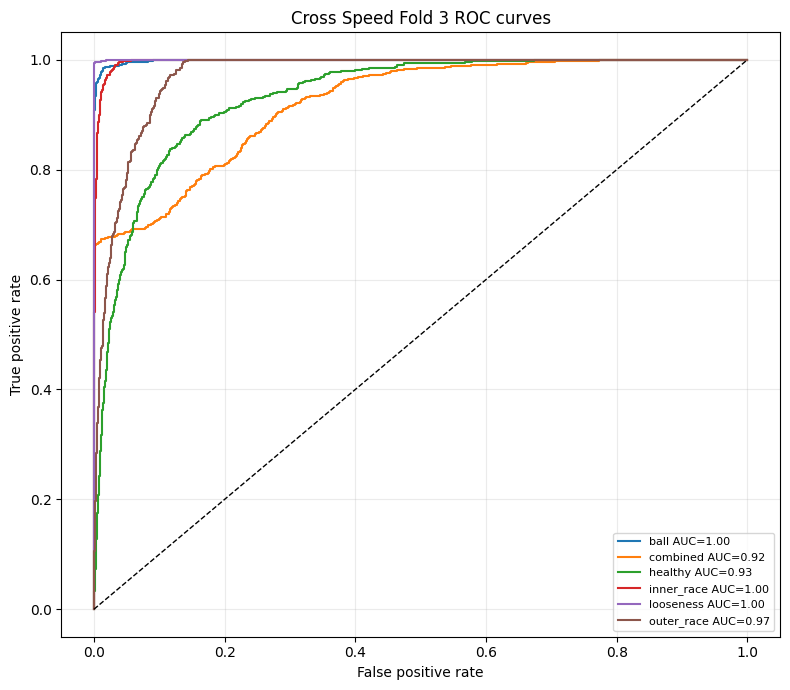

,precision,recall,f1-score,support
ball,0.837438,0.990676,0.907635,858.000000
combined,0.906639,0.679627,0.776889,643.000000
healthy,0.944444,0.034553,0.066667,492.000000
inner_race,0.955847,0.933566,0.944575,858.000000
looseness,0.964824,0.994819,0.979592,579.000000
outer_race,0.494217,0.997877,0.661041,471.000000
accuracy,0.807742,0.807742,0.807742,0.807742
macro avg,0.850568,0.771853,0.722733,3901.000000
weighted avg,0.865851,0.807742,0.769051,3901.000000


accuracy                                                                  0.807742
weighted_precision                                                        0.865851
weighted_recall                                                           0.807742
weighted_f1                                                               0.769051
macro_precision                                                           0.850568
macro_recall                                                              0.771853
macro_f1                                                                  0.722733
roc_auc                                                                   0.974336
experiment                                                      Cross Speed Fold 3
training_time_sec                                                      1409.771637
inference_time_sec                                                       98.734698
best_epoch                                                                       3
chec

,train,val,test
fault,,,
ball,1287,429,858
combined,1072,214,643
healthy,770,214,492
inner_race,1287,429,858
looseness,944,214,579
outer_race,513,429,471


Epoch 1/10


Train:   0%|          | 0/184 [00:00<?, ?it/s]

Validate:   0%|          | 0/61 [00:00<?, ?it/s]

... (24 outputs left out)

train_loss=0.4399 train_f1=0.9978 val_loss=0.9241 val_f1=0.6708
Epoch 10/10


Train:   0%|          | 0/184 [00:00<?, ?it/s]

Validate:   0%|          | 0/61 [00:00<?, ?it/s]

train_loss=0.4387 train_f1=0.9984 val_loss=1.0082 val_f1=0.6417


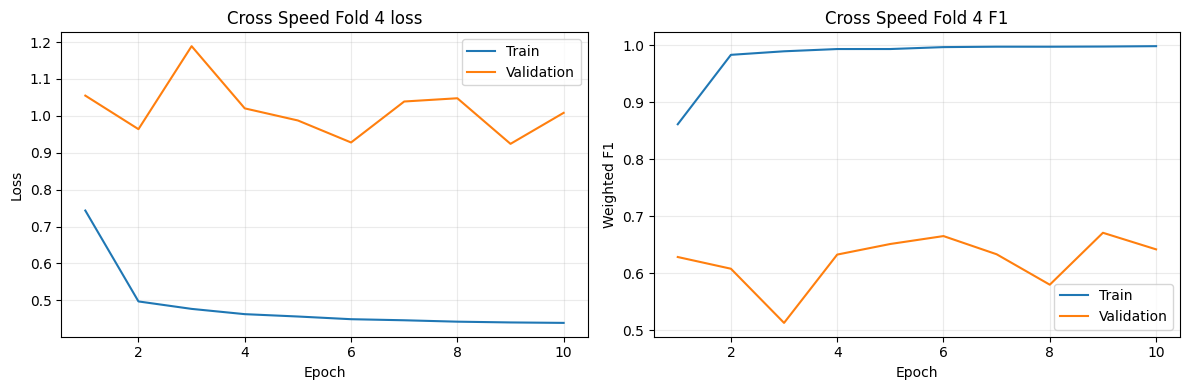

Predict:   0%|          | 0/122 [00:00<?, ?it/s]

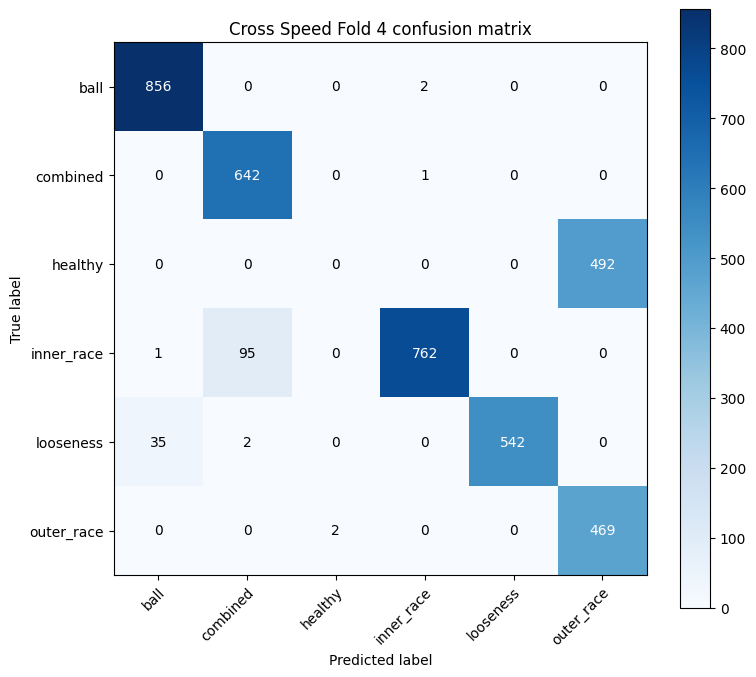

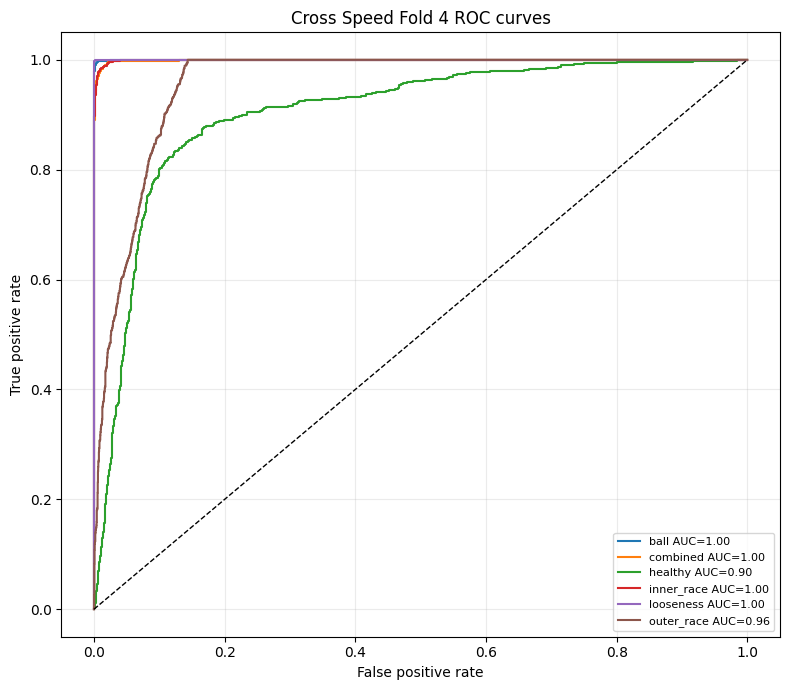

,precision,recall,f1-score,support
ball,0.959641,0.997669,0.978286,858.000000
combined,0.868742,0.998445,0.929088,643.000000
healthy,0.000000,0.000000,0.000000,492.000000
inner_race,0.996078,0.888112,0.939002,858.000000
looseness,1.000000,0.936097,0.966994,579.000000
outer_race,0.488033,0.995754,0.655028,471.000000
accuracy,0.838503,0.838503,0.838503,0.838503
macro avg,0.718749,0.802679,0.744733,3901.000000
weighted avg,0.780690,0.838503,0.797448,3901.000000


accuracy                                                                  0.838503
weighted_precision                                                         0.78069
weighted_recall                                                           0.838503
weighted_f1                                                               0.797448
macro_precision                                                           0.718749
macro_recall                                                              0.802679
macro_f1                                                                  0.744733
roc_auc                                                                   0.982374
experiment                                                      Cross Speed Fold 4
training_time_sec                                                      2342.928587
inference_time_sec                                                        89.05312
best_epoch                                                                       9
chec

,accuracy,weighted_precision,weighted_recall,weighted_f1,macro_precision,macro_recall,macro_f1,roc_auc,experiment,training_time_sec,inference_time_sec,best_epoch,checkpoint
0,0.632658,0.658755,0.632658,0.629302,0.678274,0.656070,0.646297,0.892287,Cross Speed Fold 1,1139.749137,87.748707,2,a:\AMU\IISA_2026\models\best_resnet18_cross_speed_fold_1.pth
1,0.903358,0.928606,0.903358,0.896532,0.908807,0.880170,0.868499,0.982121,Cross Speed Fold 2,1207.933774,96.850816,2,a:\AMU\IISA_2026\models\best_resnet18_cross_speed_fold_2.pth
2,0.807742,0.865851,0.807742,0.769051,0.850568,0.771853,0.722733,0.974336,Cross Speed Fold 3,1409.771637,98.734698,3,a:\AMU\IISA_2026\models\best_resnet18_cross_speed_fold_3.pth
3,0.838503,0.780690,0.838503,0.797448,0.718749,0.802679,0.744733,0.982374,Cross Speed Fold 4,2342.928587,89.053120,9,a:\AMU\IISA_2026\models\best_resnet18_cross_speed_fold_4.pth




CROSS-SPEED 5-FOLD RESULTS


,Mean,Std
accuracy,0.795565,0.115686
weighted_precision,0.808475,0.116778
weighted_recall,0.795565,0.115686
weighted_f1,0.773083,0.110337
macro_precision,0.789100,0.108535
macro_recall,0.777693,0.093009
macro_f1,0.745566,0.092176
roc_auc,0.957780,0.043821
training_time_sec,1525.095784,557.145681
inference_time_sec,93.096835,5.502484


In [92]:

def cross_speed_split(
    scalograms: pd.DataFrame,
    n_splits: int = 4,
):
    train_speeds = set(CONFIG["cross_train_speeds"])
    test_speed = CONFIG["cross_test_speed"]

    # ---------------------------------------------------
    # Training recordings (642 + 1236 RPM)
    # ---------------------------------------------------
    train_recordings = (
        scalograms[
            scalograms["speed"].isin(train_speeds)
        ][["recording_id", "fault"]]
        .drop_duplicates()
        .reset_index(drop=True)
    )

    # ---------------------------------------------------
    # Test recordings (1809 RPM ONLY)
    # ---------------------------------------------------
    test_recordings = (
        scalograms[
            scalograms["speed"] == test_speed
        ][["recording_id"]]
        .drop_duplicates()
        .reset_index(drop=True)
    )

    if train_recordings.empty:
        raise RuntimeError(
            f"No recordings found for training speeds {sorted(train_speeds)}."
        )

    if test_recordings.empty:
        raise RuntimeError(
            f"No recordings found for test speed {test_speed}."
        )

    skf = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=SEED,
    )

    folds = []

    print("\n=========================================")
    print("Cross-Speed Stratified 4-Fold Summary")
    print("=========================================")

    for fold_idx, (train_idx, val_idx) in enumerate(
        skf.split(
            train_recordings["recording_id"],
            train_recordings["fault"],
        ),
        start=1,
    ):

        train_rec = train_recordings.iloc[train_idx].reset_index(drop=True)
        val_rec = train_recordings.iloc[val_idx].reset_index(drop=True)

        train_df = scalograms[
            scalograms["recording_id"].isin(
                train_rec["recording_id"]
            )
        ].reset_index(drop=True)

        val_df = scalograms[
            scalograms["recording_id"].isin(
                val_rec["recording_id"]
            )
        ].reset_index(drop=True)

        # Test set remains ALL recordings from the unseen speed
        test_df = scalograms[
            scalograms["recording_id"].isin(
                test_recordings["recording_id"]
            )
        ].reset_index(drop=True)

        # -------------------------------------------------
        # Leakage checks
        # -------------------------------------------------
        assert (
            set(train_df.recording_id)
            & set(val_df.recording_id)
        ) == set(), "Recording leakage (train-val)"

        assert (
            set(train_df.recording_id)
            & set(test_df.recording_id)
        ) == set(), "Recording leakage (train-test)"

        assert (
            set(val_df.recording_id)
            & set(test_df.recording_id)
        ) == set(), "Recording leakage (val-test)"

        leakage = (
            set(train_df.speed)
            & set(test_df.speed)
        )

        assert not leakage, \
            f"Speed leakage detected: {leakage}"

        print(f"\nFold {fold_idx}")
        print("--------------------------")
        print(
            f"Train recordings : {train_df.recording_id.nunique()}"
        )
        print(
            f"Validation recordings : {val_df.recording_id.nunique()}"
        )
        print(
            f"Test recordings : {test_df.recording_id.nunique()}"
        )

        print(
            f"Train scalograms : {len(train_df)}"
        )
        print(
            f"Validation scalograms : {len(val_df)}"
        )
        print(
            f"Test scalograms : {len(test_df)}"
        )

        folds.append(
            (
                train_df,
                val_df,
                test_df,
            )
        )

    return folds


# ==========================================================
# Run all folds
# ==========================================================

cross_folds = cross_speed_split(scalograms_df)

cross_fold_metrics = []
cross_fold_reports = []

for fold_no, (
    train_df,
    val_df,
    test_df,
) in enumerate(cross_folds, start=1):

    print("\n")
    print("=" * 60)
    print(f"Cross-Speed Fold {fold_no}")
    print("=" * 60)

    result = run_experiment(
        f"Cross Speed Fold {fold_no}",
        train_df,
        val_df,
        test_df,
    )

    cross_fold_metrics.append(result["metrics"])
    cross_fold_reports.append(result["report"])


# ==========================================================
# Cross-speed CV summary
# ==========================================================

cross_results_df = pd.DataFrame(cross_fold_metrics)

display(cross_results_df)

print("\n")
print("=" * 60)
print("CROSS-SPEED 5-FOLD RESULTS")
print("=" * 60)

numeric_cols = cross_results_df.select_dtypes(include=np.number).columns

cross_summary = pd.DataFrame({
    "Mean": cross_results_df[numeric_cols].mean(),
    "Std": cross_results_df[numeric_cols].std(),
})

display(cross_summary)

cross_summary.to_csv(
    RESULTS_DIR / "cross_speed_cross_validation_summary.csv"
)

cross_results_df.to_csv(
    RESULTS_DIR / "cross_speed_fold_results.csv",
    index=False,
)

## 11. Generalization Gap and Comparison Figures

,Experiment,Accuracy,Accuracy Std,Weighted Precision,Weighted Recall,Weighted F1,Macro Precision,Macro Recall,Macro F1,ROC AUC,Generalization Gap,Training Time,Inference Time
0,Within Speed (5-Fold CV),0.690489,0.175025,0.766563,0.690489,0.666529,0.683531,0.681254,0.622672,0.924208,NaN,1655.531453,60.561273
1,Cross Speed 642+1236 → 1809,0.708280,NaN,0.722585,0.708280,0.667189,0.677253,0.695073,0.634113,0.926293,-0.017791,2068.288891,97.514918


,Class,Precision,Recall,F1,Experiment
0,ball,0.811636,0.795571,0.773168,Within-Speed (5-Fold CV)
1,combined,0.743961,0.793301,0.658108,Within-Speed (5-Fold CV)
2,healthy,0.430098,0.548581,0.457379,Within-Speed (5-Fold CV)
3,inner_race,0.969215,0.680886,0.725007,Within-Speed (5-Fold CV)
4,looseness,0.759272,0.921554,0.807239,Within-Speed (5-Fold CV)
5,outer_race,0.387004,0.347634,0.315130,Within-Speed (5-Fold CV)
6,ball,0.832175,0.976690,0.898660,Cross-Speed
7,combined,0.520670,0.724728,0.605982,Cross-Speed
8,healthy,0.280000,0.014228,0.027079,Cross-Speed
9,inner_race,0.992874,0.487179,0.653636,Cross-Speed


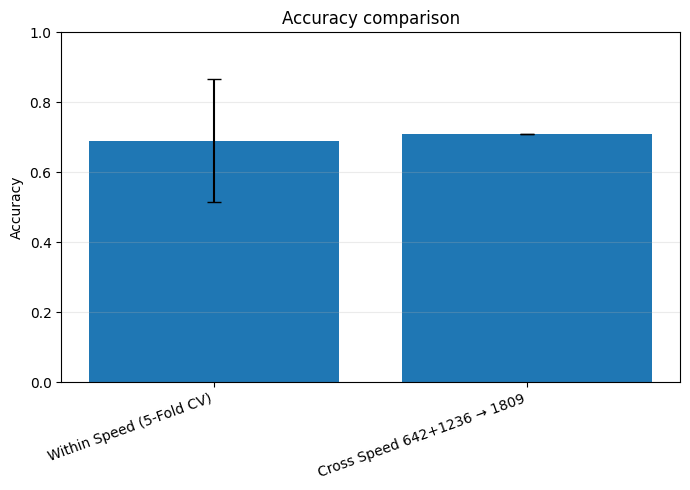

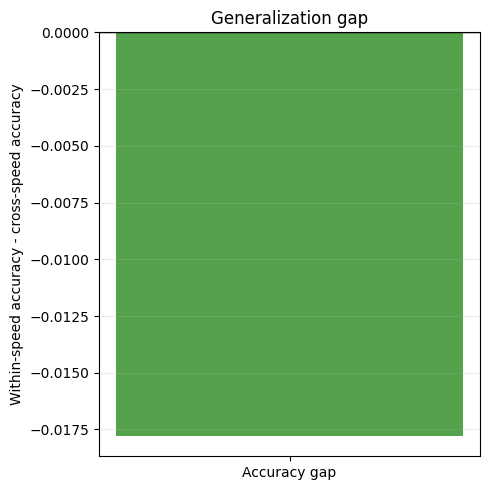

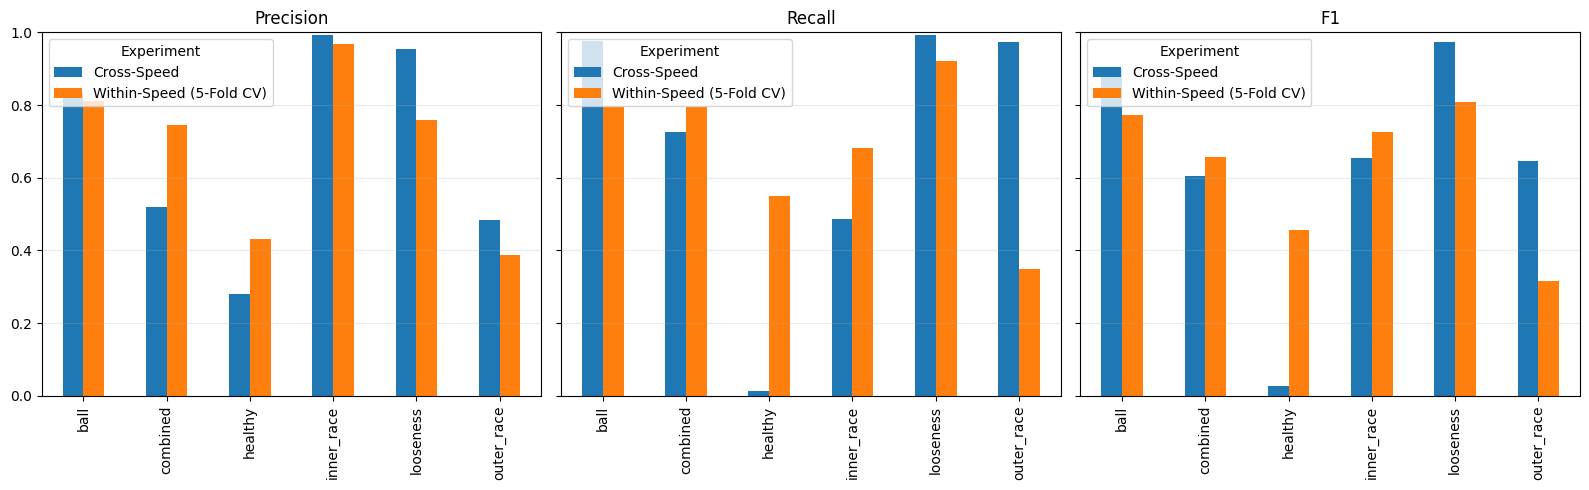

Best cross-speed class by F1: looseness (0.974)
Worst cross-speed class by F1: healthy (0.027)


In [94]:
baseline_results_df = pd.DataFrame(all_fold_metrics)

baseline_metrics = baseline_results_df.mean(numeric_only=True).to_dict()
baseline_std = baseline_results_df.std(numeric_only=True).to_dict()

cross_metrics = cross_speed_result["metrics"]

generalization_gap = (
    baseline_metrics["accuracy"]
    - cross_metrics["accuracy"]
)

summary_df = pd.DataFrame([
    {
        "Experiment": "Within Speed (5-Fold CV)",
        "Accuracy": baseline_metrics["accuracy"],
        "Accuracy Std": baseline_std["accuracy"],

        "Weighted Precision": baseline_metrics["weighted_precision"],
        "Weighted Recall": baseline_metrics["weighted_recall"],
        "Weighted F1": baseline_metrics["weighted_f1"],

        "Macro Precision": baseline_metrics["macro_precision"],
        "Macro Recall": baseline_metrics["macro_recall"],
        "Macro F1": baseline_metrics["macro_f1"],

        "ROC AUC": baseline_metrics["roc_auc"],

        "Generalization Gap": np.nan,

        "Training Time": baseline_metrics["training_time_sec"],
        "Inference Time": baseline_metrics["inference_time_sec"],
    },
    {
        "Experiment": "Cross Speed 642+1236 → 1809",

        "Accuracy": cross_metrics["accuracy"],
        "Accuracy Std": np.nan,

        "Weighted Precision": cross_metrics["weighted_precision"],
        "Weighted Recall": cross_metrics["weighted_recall"],
        "Weighted F1": cross_metrics["weighted_f1"],

        "Macro Precision": cross_metrics["macro_precision"],
        "Macro Recall": cross_metrics["macro_recall"],
        "Macro F1": cross_metrics["macro_f1"],

        "ROC AUC": cross_metrics["roc_auc"],

        "Generalization Gap": generalization_gap,

        "Training Time": cross_metrics["training_time_sec"],
        "Inference Time": cross_metrics["inference_time_sec"],
    },
])
summary_df.to_csv(RESULTS_DIR / "summary.csv", index=False)
summary_df.to_csv(RESULTS_DIR / "metrics.csv", index=False)
display(summary_df)


def per_class_from_report(report_df, experiment_name):
    rows = []
    for cls in classes:
        if cls in report_df.index:
            rows.append({
                "Experiment": experiment_name,
                "Class": cls,
                "Precision": report_df.loc[cls, "precision"],
                "Recall": report_df.loc[cls, "recall"],
                "F1": report_df.loc[cls, "f1-score"],
            })
    return rows


# ======================================================
# Average classification report over 5 folds
# ======================================================

fold_reports = []

for report in all_fold_reports:

    df = report.copy()

    df["Class"] = df.index

    df = df[df["Class"].isin(classes)]

    fold_reports.append(
        df[
            [
                "Class",
                "precision",
                "recall",
                "f1-score",
            ]
        ]
    )

fold_report_df = pd.concat(fold_reports)

baseline_average = (
    fold_report_df
    .groupby("Class")
    .mean()
    .reset_index()
)

baseline_average["Experiment"] = "Within-Speed (5-Fold CV)"

cross_report = (
    cross_speed_result["report"]
    .copy()
    .reset_index()
    .rename(columns={"index": "Class"})
)

cross_report = cross_report[
    cross_report["Class"].isin(classes)
]

cross_report["Experiment"] = "Cross-Speed"

cross_report = cross_report[
    [
        "Class",
        "precision",
        "recall",
        "f1-score",
        "Experiment",
    ]
]

baseline_average = baseline_average.rename(
    columns={
        "precision": "Precision",
        "recall": "Recall",
        "f1-score": "F1",
    }
)

cross_report = cross_report.rename(
    columns={
        "precision": "Precision",
        "recall": "Recall",
        "f1-score": "F1",
    }
)

per_class_df = pd.concat(
    [
        baseline_average,
        cross_report,
    ],
    ignore_index=True,
)

per_class_df.to_csv(
    RESULTS_DIR / "per_class_comparison.csv",
    index=False,
)

display(per_class_df)

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(
    summary_df["Experiment"],
    summary_df["Accuracy"],
    yerr=summary_df["Accuracy Std"].fillna(0),
    capsize=5,
)
ax.set_ylim(0, 1)
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy comparison")
ax.grid(axis="y", alpha=0.25)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
fig.tight_layout()
fig.savefig(FIG_DIR / "accuracy_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
ax.bar(["Accuracy gap"], [generalization_gap], color="#54a24b")
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Within-speed accuracy - cross-speed accuracy")
ax.set_title("Generalization gap")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "generalization_gap.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, metric in zip(axes, ["Precision", "Recall", "F1"]):
    pivot = per_class_df.pivot(index="Class", columns="Experiment", values=metric).reindex(classes)
    pivot.plot(kind="bar", ax=ax)
    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.25)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "per_class_metric_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

cross_f1 = per_class_df[per_class_df["Experiment"].eq("Cross-Speed")].set_index("Class")["F1"]
best_class = cross_f1.idxmax()
worst_class = cross_f1.idxmin()
print(f"Best cross-speed class by F1: {best_class} ({cross_f1.loc[best_class]:.3f})")
print(f"Worst cross-speed class by F1: {worst_class} ({cross_f1.loc[worst_class]:.3f})")

## 12. Feature Embedding Visualization

Extract features:   0%|          | 0/63 [00:00<?, ?it/s]

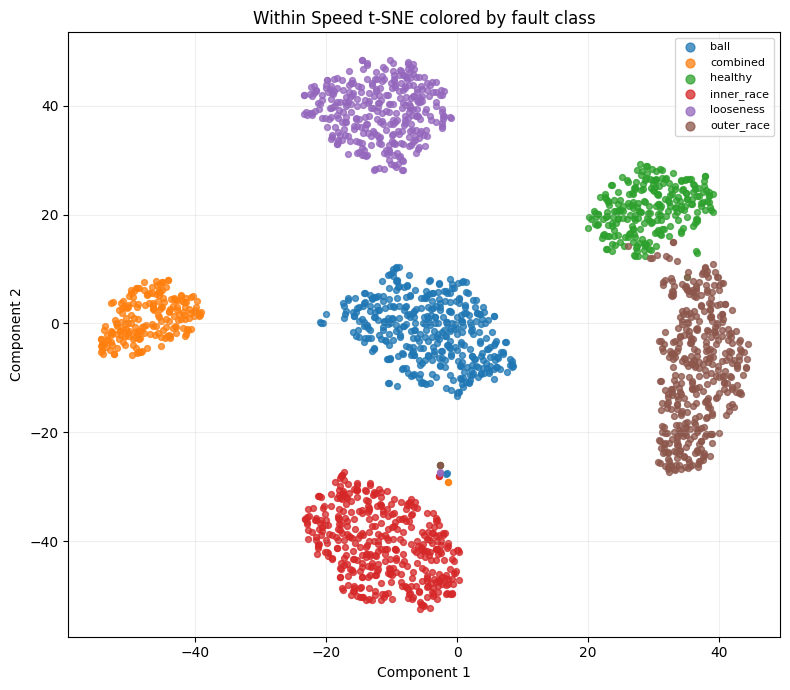

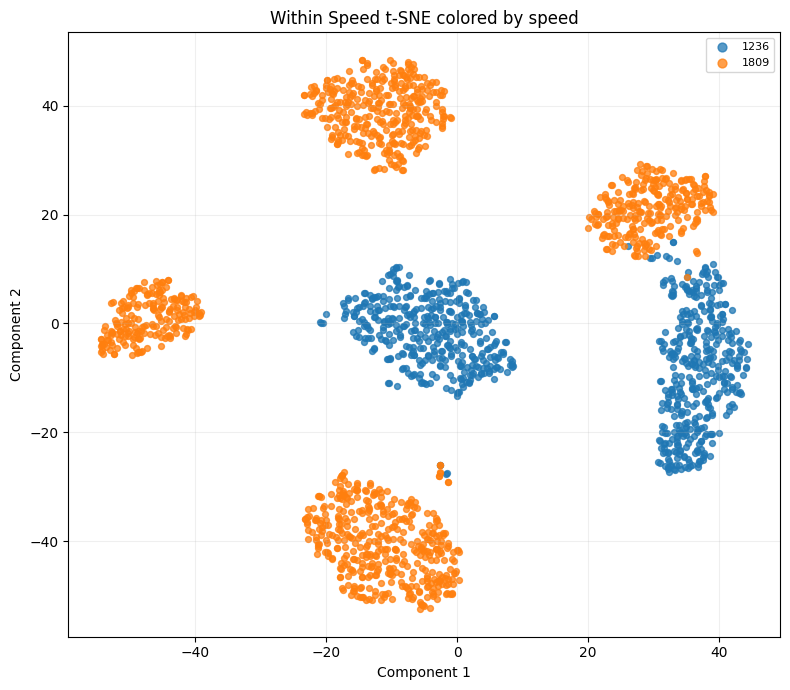

C:\Users\Ahmad Zakariya\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


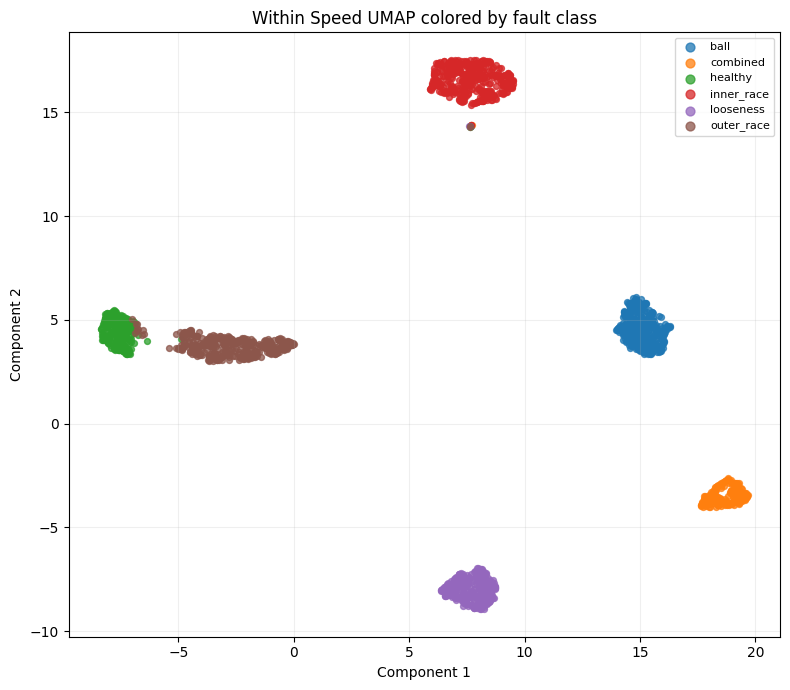

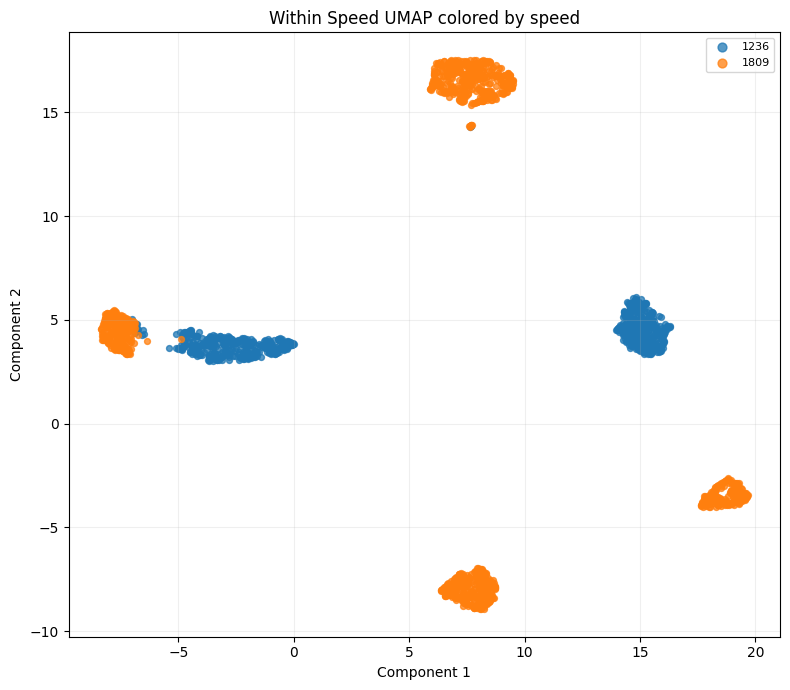

Extract features:   0%|          | 0/63 [00:00<?, ?it/s]

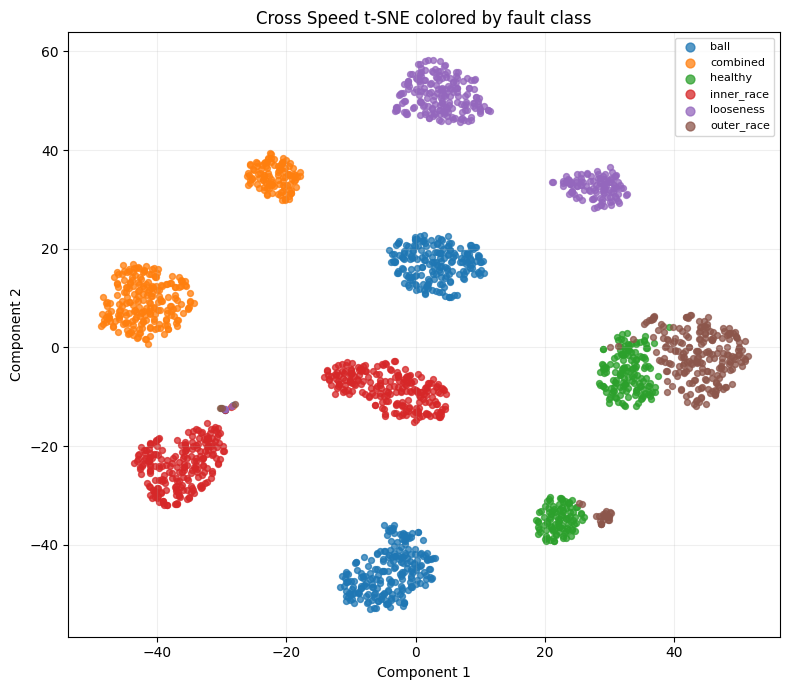

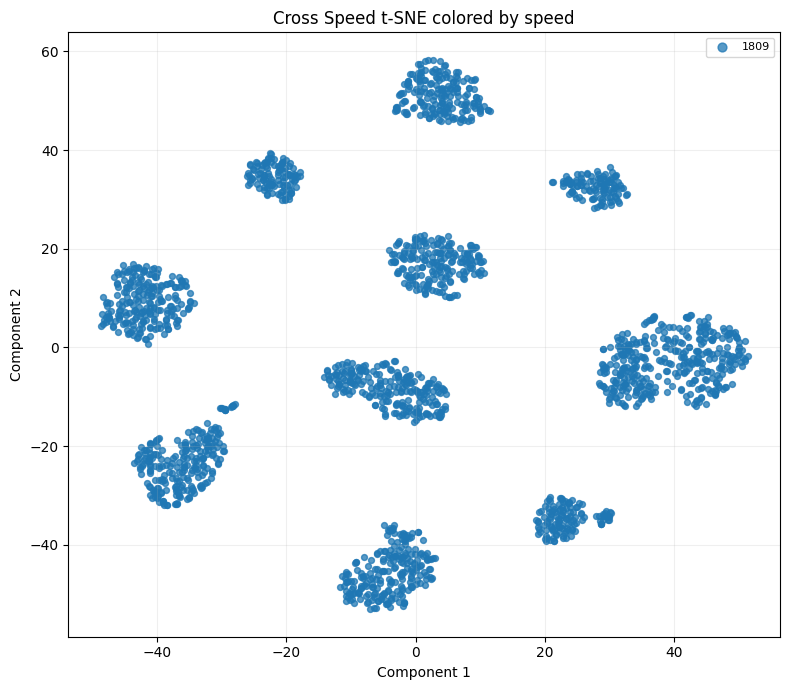

C:\Users\Ahmad Zakariya\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


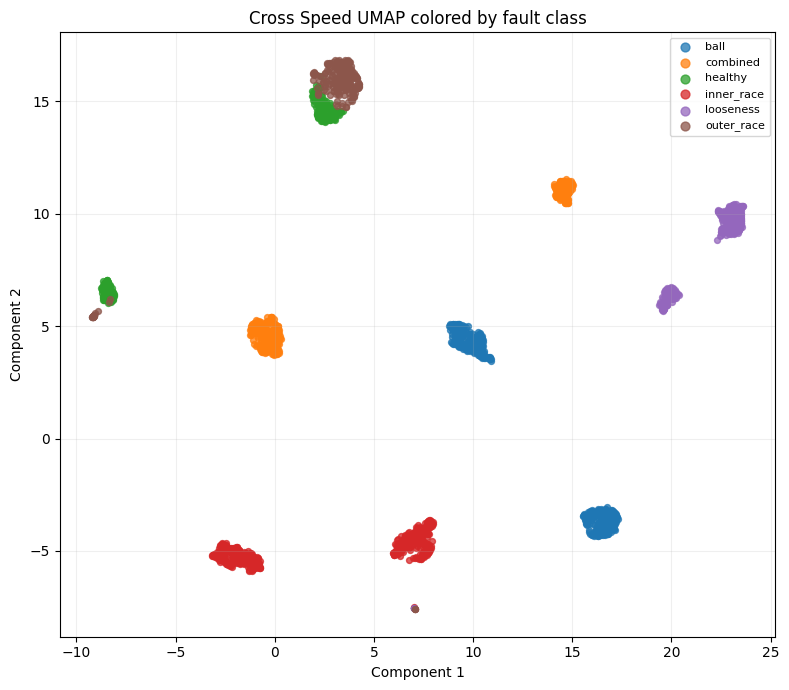

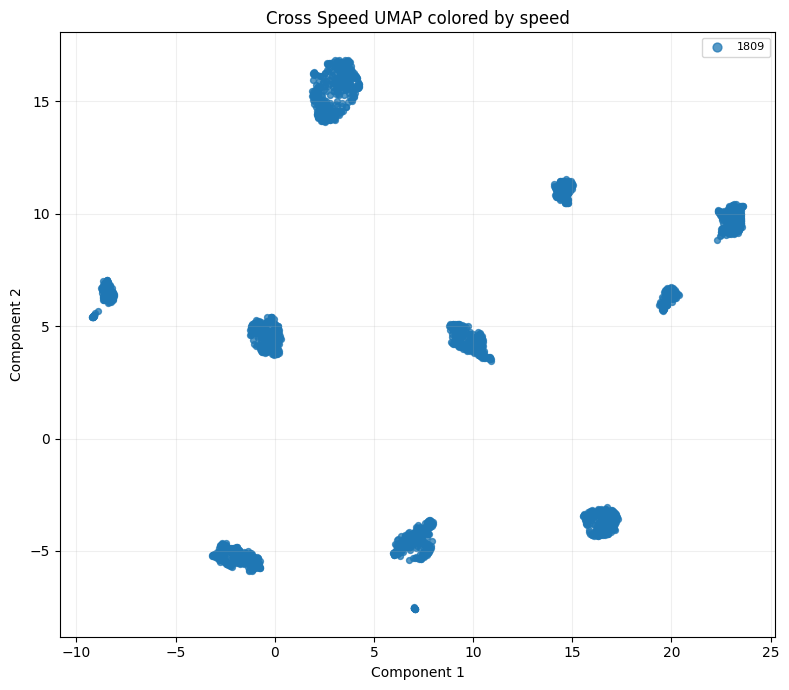

In [95]:
def extract_features(model, df: pd.DataFrame):
    if len(df) > CONFIG["max_embedding_samples"]:
        df = df.sample(CONFIG["max_embedding_samples"], random_state=SEED).reset_index(drop=True)
    loader = make_loader(df, "test", shuffle=False)
    features, labels, speeds = [], [], []

    def hook_fn(module, inputs, output):
        features.append(output.detach().cpu().flatten(start_dim=1).numpy())

    handle = model.avgpool.register_forward_hook(hook_fn)
    model.eval()
    with torch.no_grad():
        for images, batch_labels, metas in tqdm(loader, desc="Extract features"):
            images = images.to(DEVICE, non_blocking=True)
            _ = model(images)
            labels.extend([idx_to_class[int(i)] for i in batch_labels.numpy()])
            speeds.extend(list(metas["speed"]))
    handle.remove()
    feature_matrix = np.vstack(features) if features else np.empty((0, 0))
    meta_df = pd.DataFrame({"fault": labels, "speed": speeds})
    return feature_matrix, meta_df


def plot_embedding(embedding, meta_df, color_by, title, out_path):
    fig, ax = plt.subplots(figsize=(8, 7))
    categories = sorted(meta_df[color_by].astype(str).unique())
    cmap = plt.get_cmap("tab10")
    for i, category in enumerate(categories):
        mask = meta_df[color_by].astype(str).eq(category).values
        ax.scatter(embedding[mask, 0], embedding[mask, 1], s=18, alpha=0.75, label=category, color=cmap(i % 10))
    ax.set_title(title)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.legend(markerscale=1.5, fontsize=8)
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()

for experiment_name, result, test_df in [
    ("Within Speed", baseline_result, baseline_test_df),
    ("Cross Speed", cross_speed_result, cross_test_df),
]:
    features, feature_meta = extract_features(
        result["model"],
        test_df.reset_index(drop=True),
    )

    if len(features) >= 3:
        perplexity = max(2, min(30, (len(features) - 1) // 3))

        tsne_embedding = TSNE(
            n_components=2,
            perplexity=perplexity,
            learning_rate="auto",
            init="pca",
            random_state=SEED,
        ).fit_transform(features)

        plot_embedding(
            tsne_embedding,
            feature_meta,
            "fault",
            f"{experiment_name} t-SNE colored by fault class",
            RESULTS_DIR / "tsne" / f"{slugify(experiment_name)}_tsne_by_fault.png",
        )

        plot_embedding(
            tsne_embedding,
            feature_meta,
            "speed",
            f"{experiment_name} t-SNE colored by speed",
            RESULTS_DIR / "tsne" / f"{slugify(experiment_name)}_tsne_by_speed.png",
        )

        if not QUICK_RUN:
            try:
                import umap.umap_ as umap
                UMAP_AVAILABLE = True
                UMAP_IMPORT_ERROR = None
            except Exception as exc:
                UMAP_AVAILABLE = False
                UMAP_IMPORT_ERROR = exc

        if UMAP_AVAILABLE:
            umap_embedding = umap.UMAP(
                n_components=2,
                random_state=SEED,
                n_neighbors=min(15, len(features) - 1),
            ).fit_transform(features)

            plot_embedding(
                umap_embedding,
                feature_meta,
                "fault",
                f"{experiment_name} UMAP colored by fault class",
                RESULTS_DIR / "umap" / f"{slugify(experiment_name)}_umap_by_fault.png",
            )

            plot_embedding(
                umap_embedding,
                feature_meta,
                "speed",
                f"{experiment_name} UMAP colored by speed",
                RESULTS_DIR / "umap" / f"{slugify(experiment_name)}_umap_by_speed.png",
            )
        else:
            print(f"UMAP is unavailable: {UMAP_IMPORT_ERROR}. Install umap-learn to enable UMAP plots.")
    else:
        print(f"Not enough feature vectors for {experiment_name}.")

## 13. Final Summary

In [97]:
summary_df = pd.read_csv(RESULTS_DIR / "summary.csv")
baseline_row = summary_df[
    summary_df["Experiment"].str.contains("Within")
].iloc[0]
cross_row = summary_df[summary_df["Experiment"].str.contains("Cross", case=False)].iloc[0]
total_training_time = summary_df["Training Time"].sum()
total_inference_time = summary_df["Inference Time"].sum()

print("=" * 38)
print("Bearing Fault Diagnosis Summary")
print("=" * 38)
print("\nDataset")
print("-------")
print(f"Number of recordings : {len(recordings_df)}")
print(f"Number of segments   : {len(segments_df)}")
print(f"Fault classes        : {', '.join(classes)}")
print(f"Acquisition methods  : {', '.join(sorted(recordings_df['acquisition'].unique()))}")
print(f"Speeds               : {', '.join(sorted(recordings_df['speed'].unique()))}")

print("\nExperiment 1 (Within-Speed 5-Fold CV)")
print("--------------------------------------")
print(f"Accuracy            : {baseline_row['Accuracy']:.4f} ± {baseline_row['Accuracy Std']:.4f}")
print(f"Weighted Precision  : {baseline_row['Weighted Precision']:.4f}")
print(f"Weighted Recall     : {baseline_row['Weighted Recall']:.4f}")
print(f"Weighted F1-score   : {baseline_row['Weighted F1']:.4f}")
print(f"Macro F1-score      : {baseline_row['Macro F1']:.4f}")
print(f"ROC-AUC             : {baseline_row['ROC AUC']:.4f}")

print("\nExperiment 2 (Cross-Speed 4-Fold CV)")
print("------------------------------------")
print(f"Accuracy            : {cross_row['Accuracy']:.4f} ± {cross_row['Accuracy Std']:.4f}")
print(f"Weighted Precision  : {cross_row['Weighted Precision']:.4f}")
print(f"Weighted Recall     : {cross_row['Weighted Recall']:.4f}")
print(f"Weighted F1-score   : {cross_row['Weighted F1']:.4f}")
print(f"Macro F1-score      : {cross_row['Macro F1']:.4f}")
print(f"ROC-AUC             : {cross_row['ROC AUC']:.4f}")

print("\nGeneralization Gap")
print("------------------")
print(f"Accuracy Gap : {generalization_gap:.4f}")
print(f"Worst class  : {worst_class}")
print(f"Best class   : {best_class}")

print(f"\nTraining Time : {total_training_time:.2f} sec")
print(f"Inference Time: {total_inference_time:.2f} sec")
print(f"GPU Used      : {DEVICE.type == 'cuda'} ({DEVICE})")
print("=" * 38)

Bearing Fault Diagnosis Summary

Dataset
-------
Number of recordings : 36
Number of segments   : 11703
Fault classes        : ball, combined, healthy, inner_race, looseness, outer_race
Acquisition methods  : with_stethoscope, without_stethoscope
Speeds               : 1236, 1809, 642

Experiment 1 (Within-Speed 5-Fold CV)
--------------------------------------
Accuracy            : 0.6905 ± 0.1750
Weighted Precision  : 0.7666
Weighted Recall     : 0.6905
Weighted F1-score   : 0.6665
Macro F1-score      : 0.6227
ROC-AUC             : 0.9242

Experiment 2 (Cross-Speed 4-Fold CV)
------------------------------------
Accuracy            : 0.7083 ± nan
Weighted Precision  : 0.7226
Weighted Recall     : 0.7083
Weighted F1-score   : 0.6672
Macro F1-score      : 0.6341
ROC-AUC             : 0.9263

Generalization Gap
------------------
Accuracy Gap : -0.0178
Worst class  : healthy
Best class   : looseness

Training Time : 3723.82 sec
Inference Time: 158.08 sec
GPU Used      : False (cpu)


## Required Python Packages

Install the required packages with:

```bash
pip install numpy pandas scipy PyWavelets matplotlib scikit-learn torch torchvision tqdm umap-learn pillow ipykernel nbconvert
```